DTW_MCYT


Phase A: Baseline

In [ ]:
from google.colab import files
uploaded = files.upload()
!unrar x MCYT.rar
!ls
!find . -maxdepth 2 -type d | head -30

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
Extracting  MCYT/firmas/0312/0312f13.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f14.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f15.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f16.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f17.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f18.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f19.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f20.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f21.fpg                                  63%  OK 
Extracting  MCYT/firmas/0312/0312f22.fpg                                  63%  OK 
Ex

In [ ]:
MCYT_ROOT = "/content/MCYT"
import os

print(os.path.exists("/content/MCYT/firmas"))

True


In [ ]:
!pip install dtaidistance tqdm
!apt-get install unrar -y

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 32.9 MB/s eta 0:00:00
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:6.1.5-1ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 3 not upgraded.


In [ ]:
!pip install numba

In [ ]:
import os
import struct
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from dtaidistance import dtw_ndim


# ============================================================
# PARAMÈTRES
# ============================================================

MCYT_ROOT = "/content/MCYT"  # doit contenir /firmas
POINT = 11

TRAIN_SIGNATURES = [1, 2, 3, 4, 5]      # v01-v05
TEST_SIGNATURES = [6, 7, 8, 9, 10]      # v06-v10
SKILLED_FORGERIES = list(range(0, 25))  # f00-f24

MAX_USERS = 10  # mets None pour tout MCYT


# ============================================================
# DTW code that I am not allowed to share


# ============================================================
# DET / DCF / EER
# ============================================================

def compute_det(true_scores, impostor_scores):
    true_scores = np.asarray(true_scores, dtype=np.float64)
    impostor_scores = np.asarray(impostor_scores, dtype=np.float64)

    scores = np.concatenate([true_scores, impostor_scores])
    thresholds = np.sort(scores)

    P_miss = []
    P_fa = []

    for th in thresholds:
        miss = np.mean(true_scores < th)
        fa = np.mean(impostor_scores >= th)

        P_miss.append(miss)
        P_fa.append(fa)

    return np.array(P_miss), np.array(P_fa)


def min_dcf(P_miss, P_fa, C_miss=1, C_fa=1, P_target=0.5):
    dcf = C_miss * P_target * P_miss + C_fa * (1 - P_target) * P_fa
    idx = np.argmin(dcf)

    return dcf[idx], P_miss[idx], P_fa[idx]


def compute_eer(P_miss, P_fa):
    idx = np.argmin(np.abs(P_miss - P_fa))
    eer = (P_miss[idx] + P_fa[idx]) / 2
    return eer, P_miss[idx], P_fa[idx]


# ============================================================
# Visualisation d'une signature
# ============================================================

def plot_one_signature(firmante=0, letra="v", firma=1):
    path = signature_path(MCYT_ROOT, firmante, letra, firma)

    print("Loading:", path)
    print("Exists:", os.path.exists(path))

    vect, n, m, fs = leer_firma(path)
    vect = traslada_firma(vect)

    print("Shape:", vect.shape)
    print("Fs:", fs)

    plt.figure(figsize=(6, 6))
    plt.plot(vect[:, 0], -vect[:, 1])
    plt.title(f"MCYT signature {firmante:04d}{letra}{firma:02d}")
    plt.axis("equal")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(10, 3))
    plt.plot(vect[:, 2])
    plt.title("Pressure")
    plt.grid(True)
    plt.show()


# ============================================================
# MAIN DTW
# ============================================================

def run_main_dtw():
    users = get_mcyt_users(MAX_USERS)

    print("MCYT_ROOT:", MCYT_ROOT)
    print("Firmas exists:", os.path.exists(os.path.join(MCYT_ROOT, "firmas")))
    print("POINT:", POINT)
    print("Users:", len(users))
    print("First users:", users[:10])

    # -------------------------
    # Train signatures
    # -------------------------
    print("\nLeyendo firmas train")

    modelo = {}

    for firmante in tqdm(users):
        modelo[firmante] = []

        for firma in TRAIN_SIGNATURES:
            vectn = load_signature_features(firmante, "v", firma)
            modelo[firmante].append(vectn)

    # -------------------------
    # Genuine test signatures
    # -------------------------
    print("\nCalculando distancias genuine test")

    mat_d = {}

    for firmante in tqdm(users):
        mat_d[firmante] = {}

        for candidate in users:
            mat_d[firmante][candidate] = []

        for firma in range(1, 6):
            firma_test = firma + 5  # v06-v10
            vectn = load_signature_features(firmante, "v", firma_test)

            for candidate in users:
                d = model_distance(vectn, modelo[candidate])
                mat_d[firmante][candidate].append(d)

    # -------------------------
    # ID RATE
    # -------------------------
    acierto = 0
    error = 0

    for firma_index in range(5):
        for firmante in users:
            distances = [
                mat_d[firmante][candidate][firma_index]
                for candidate in users
            ]

            predicted_idx = int(np.argmin(distances))
            predicted_user = users[predicted_idx]

            if predicted_user == firmante:
                acierto += 1
            else:
                error += 1

    tasa = 100 * acierto / (acierto + error)

    # -------------------------
    # Random forgeries scores
    # -------------------------
    true_speaker_scores = []
    impostor_scores = []

    for i_user in users:
        for j_user in users:
            scores = [
                -mat_d[i_user][j_user][firma_index]
                for firma_index in range(5)
            ]

            if i_user == j_user:
                true_speaker_scores.extend(scores)
            else:
                impostor_scores.extend(scores)

    true_speaker_scores = np.array(true_speaker_scores)
    impostor_scores = np.array(impostor_scores)

    P_miss, P_fa = compute_det(true_speaker_scores, impostor_scores)
    DCF_opt, Popt_miss, Popt_fa = min_dcf(P_miss, P_fa)
    EER, EER_miss, EER_fa = compute_eer(P_miss, P_fa)

    # -------------------------
    # Skilled forgeries
    # -------------------------
    print("\nCalculando distancias skilled forgeries")

    impostor_scoresS = []

    for firmante in tqdm(users):
        for firma in SKILLED_FORGERIES:
            vectn = load_signature_features(firmante, "f", firma)
            d = model_distance(vectn, modelo[firmante])
            impostor_scoresS.append(-d)

    impostor_scoresS = np.array(impostor_scoresS)

    P_missS, P_faS = compute_det(true_speaker_scores, impostor_scoresS)
    DCF_optS, Popt_missS, Popt_faS = min_dcf(P_missS, P_faS)
    EERS, EERS_miss, EERS_fa = compute_eer(P_missS, P_faS)

    # -------------------------
    # Results
    # -------------------------
    print("\n===== MAIN DTW RESULTS =====")
    print(f"POINT = {POINT}")
    print(f"Users = {len(users)}")

    print("\nIdentification")
    print(f"DTW Ident.(%) = {tasa:.4f}")

    print("\nRandom forgeries")
    print(f"DCF_opt = {DCF_opt:.6f}")
    print(f"DCF_opt (%) = {DCF_opt * 100:.4f}")
    print(f"Pmiss@DCF = {Popt_miss:.6f}")
    print(f"Pfa@DCF = {Popt_fa:.6f}")
    print(f"EER = {EER:.6f}")
    print(f"EER (%) = {EER * 100:.4f}")

    print("\nSkilled forgeries")
    print(f"DCF_optS = {DCF_optS:.6f}")
    print(f"DCF_optS (%) = {DCF_optS * 100:.4f}")
    print(f"PmissS@DCF = {Popt_missS:.6f}")
    print(f"PfaS@DCF = {Popt_faS:.6f}")
    print(f"EER skilled = {EERS:.6f}")
    print(f"EER skilled (%) = {EERS * 100:.4f}")

    return {
        "id_rate": tasa,
        "dcf_random": DCF_opt,
        "dcf_random_percent": DCF_opt * 100,
        "dcf_skilled": DCF_optS,
        "dcf_skilled_percent": DCF_optS * 100,
        "eer_random": EER,
        "eer_skilled": EERS,
    }

Loading: /content/MCYT/firmas/0000/0000v01.fpg
Exists: True
Shape: (103, 5)
Fs: 100


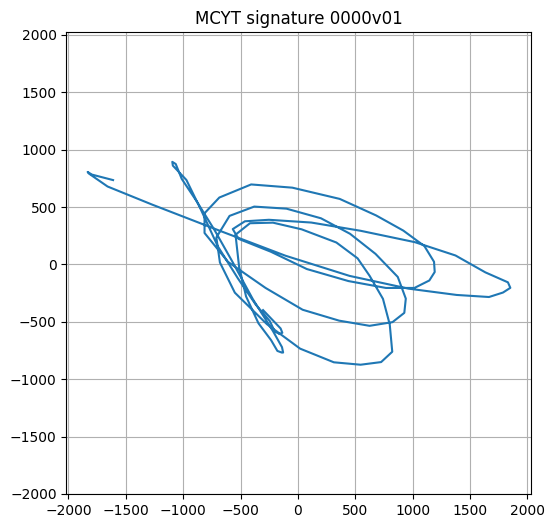

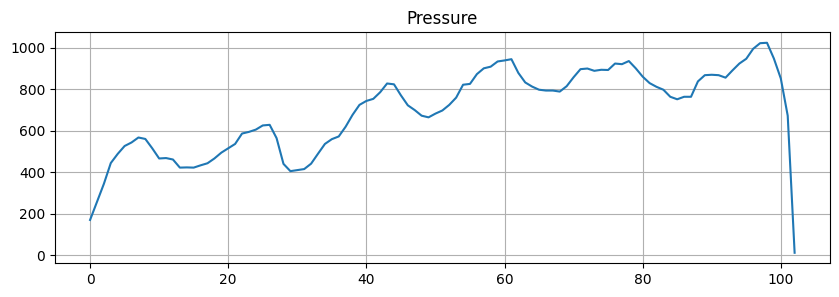

In [ ]:
plot_one_signature(firmante=0, letra="v", firma=1)

In [ ]:
MAX_USERS = 10
results = run_main_dtw()

MCYT_ROOT: /content/MCYT
Firmas exists: True
POINT: 11
Users: 10
First users: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Leyendo firmas train


100%|██████████| 10/10 [00:00<00:00, 18.91it/s]



Calculando distancias genuine test


100%|██████████| 10/10 [00:04<00:00,  2.16it/s]



Calculando distancias skilled forgeries


100%|██████████| 10/10 [00:06<00:00,  1.44it/s]


===== MAIN DTW RESULTS =====
POINT = 11
Users = 10

Identification
DTW Ident.(%) = 100.0000

Random forgeries
DCF_opt = 0.000000
DCF_opt (%) = 0.0000
Pmiss@DCF = 0.000000
Pfa@DCF = 0.000000
EER = 0.000000
EER (%) = 0.0000

Skilled forgeries
DCF_optS = 0.026000
DCF_optS (%) = 2.6000
PmissS@DCF = 0.020000
PfaS@DCF = 0.032000
EER skilled = 0.036000
EER skilled (%) = 3.6000


In [ ]:
MAX_USERS = None
results = run_main_dtw()

MCYT_ROOT: /content/MCYT
Firmas exists: True
POINT: 11
Users: 330
First users: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Leyendo firmas train


100%|██████████| 330/330 [00:29<00:00, 11.26it/s]



Calculando distancias genuine test


100%|██████████| 330/330 [1:40:36<00:00, 18.29s/it]



Calculando distancias skilled forgeries


100%|██████████| 330/330 [07:16<00:00,  1.32s/it]



===== MAIN DTW RESULTS =====
POINT = 11
Users = 330

Identification
DTW Ident.(%) = 99.0303

Random forgeries
DCF_opt = 0.005838
DCF_opt (%) = 0.5838
Pmiss@DCF = 0.009697
Pfa@DCF = 0.001978
EER = 0.007971
EER (%) = 0.7971

Skilled forgeries
DCF_optS = 0.038121
DCF_optS (%) = 3.8121
PmissS@DCF = 0.041212
PfaS@DCF = 0.035030
EER skilled = 0.038788
EER skilled (%) = 3.8788


Phase B: Analyse d'1 user

In [ ]:
# ============================================================
# PHASE B — SINGLE SUBJECT ANALYSIS
# ============================================================

SINGLE_USER = 1  # tu peux changer : 0, 1, 2, etc.


def load_raw_signature(firmante, letra="v", firma=1):
    path = signature_path(MCYT_ROOT, firmante, letra, firma)

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    vect, n, m, fs = leer_firma(path)
    vect = traslada_firma(vect)

    return vect


def plot_signature_xy(vect, title="Signature"):
    x = vect[:, 0]
    y = vect[:, 1]

    plt.figure(figsize=(6, 6))
    plt.plot(x, -y)
    plt.title(title)
    plt.axis("equal")
    plt.grid(True)
    plt.show()


def plot_signal(signal, title="Signal", ylabel="Value"):
    plt.figure(figsize=(10, 3))
    plt.plot(signal)
    plt.title(title)
    plt.xlabel("Point index")
    plt.ylabel(ylabel)
    plt.grid(True)
    plt.show()


def plot_train_test_xy(user_id):
    train_ids = [1, 2, 3, 4, 5]
    test_ids = [6, 7, 8, 9, 10]

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    for sig_id in train_ids:
        vect = load_raw_signature(user_id, "v", sig_id)
        plt.plot(vect[:, 0], -vect[:, 1], label=f"v{sig_id:02d}")
    plt.title(f"User {user_id:04d} - Train signatures")
    plt.axis("equal")
    plt.grid(True)
    plt.legend()

    plt.subplot(1, 2, 2)
    for sig_id in test_ids:
        vect = load_raw_signature(user_id, "v", sig_id)
        plt.plot(vect[:, 0], -vect[:, 1], label=f"v{sig_id:02d}")
    plt.title(f"User {user_id:04d} - Test signatures")
    plt.axis("equal")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()


def plot_all_signatures_grid(user_id):
    sig_ids = list(range(1, 11))

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()

    for i, sig_id in enumerate(sig_ids):
        vect = load_raw_signature(user_id, "v", sig_id)

        axes[i].plot(vect[:, 0], -vect[:, 1])
        axes[i].set_title(f"v{sig_id:02d}")
        axes[i].axis("equal")
        axes[i].grid(True)

    plt.suptitle(f"User {user_id:04d} - Genuine signatures v01-v10")
    plt.tight_layout()
    plt.show()


def plot_pressure_grid(user_id):
    sig_ids = list(range(1, 11))

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()

    for i, sig_id in enumerate(sig_ids):
        vect = load_raw_signature(user_id, "v", sig_id)
        pressure = vect[:, 2]

        axes[i].plot(pressure)
        axes[i].set_title(f"Pressure v{sig_id:02d}")
        axes[i].grid(True)

    plt.suptitle(f"User {user_id:04d} - Pressure signals")
    plt.tight_layout()
    plt.show()


def plot_azimuth_altitude_pressure(user_id, sig_id=1):
    vect = load_raw_signature(user_id, "v", sig_id)

    x = vect[:, 0]
    y = vect[:, 1]
    pressure = vect[:, 2]

    # Selon MCYT : colonnes probables
    # 0 = X, 1 = Y, 2 = pressure, 3 = azimuth, 4 = inclination/altitude
    azimuth = vect[:, 3] if vect.shape[1] > 3 else None
    altitude = vect[:, 4] if vect.shape[1] > 4 else None

    plt.figure(figsize=(6, 6))
    plt.plot(x, -y)
    plt.title(f"User {user_id:04d} - Signature v{sig_id:02d} XY")
    plt.axis("equal")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(12, 8))

    plt.subplot(3, 1, 1)
    plt.plot(pressure)
    plt.title("Pressure")
    plt.grid(True)

    plt.subplot(3, 1, 2)
    if azimuth is not None:
        plt.plot(azimuth)
    plt.title("Azimuth")
    plt.grid(True)

    plt.subplot(3, 1, 3)
    if altitude is not None:
        plt.plot(altitude)
    plt.title("Altitude / Inclination")
    plt.grid(True)

    plt.tight_layout()
    plt.show()


def single_subject_summary(user_id):
    print(f"===== SINGLE SUBJECT ANALYSIS: user {user_id:04d} =====")

    for sig_id in range(1, 11):
        vect = load_raw_signature(user_id, "v", sig_id)

        print(
            f"v{sig_id:02d} | "
            f"points={len(vect)} | "
            f"x range=({vect[:,0].min():.1f}, {vect[:,0].max():.1f}) | "
            f"y range=({vect[:,1].min():.1f}, {vect[:,1].max():.1f}) | "
            f"pressure mean={vect[:,2].mean():.2f} | "
            f"pressure std={vect[:,2].std():.2f}"
        )

===== SINGLE SUBJECT ANALYSIS: user 0007 =====
v01 | points=188 | x range=(-2008.0, 1057.0) | y range=(-260.0, 339.0) | pressure mean=283.10 | pressure std=168.66
v02 | points=188 | x range=(-2048.0, 1070.0) | y range=(-310.0, 368.0) | pressure mean=330.58 | pressure std=203.35
v03 | points=190 | x range=(-1850.0, 977.0) | y range=(-357.0, 288.0) | pressure mean=336.26 | pressure std=192.07
v04 | points=239 | x range=(-1771.0, 1370.0) | y range=(-321.0, 316.0) | pressure mean=374.13 | pressure std=215.62
v05 | points=165 | x range=(-1770.0, 1037.0) | y range=(-365.0, 317.0) | pressure mean=394.52 | pressure std=216.38
v06 | points=177 | x range=(-2006.0, 904.0) | y range=(-328.0, 281.0) | pressure mean=331.82 | pressure std=199.68
v07 | points=166 | x range=(-1678.0, 835.0) | y range=(-289.0, 351.0) | pressure mean=355.06 | pressure std=217.85
v08 | points=173 | x range=(-1849.0, 934.0) | y range=(-301.0, 309.0) | pressure mean=362.72 | pressure std=193.05
v09 | points=186 | x range=(-

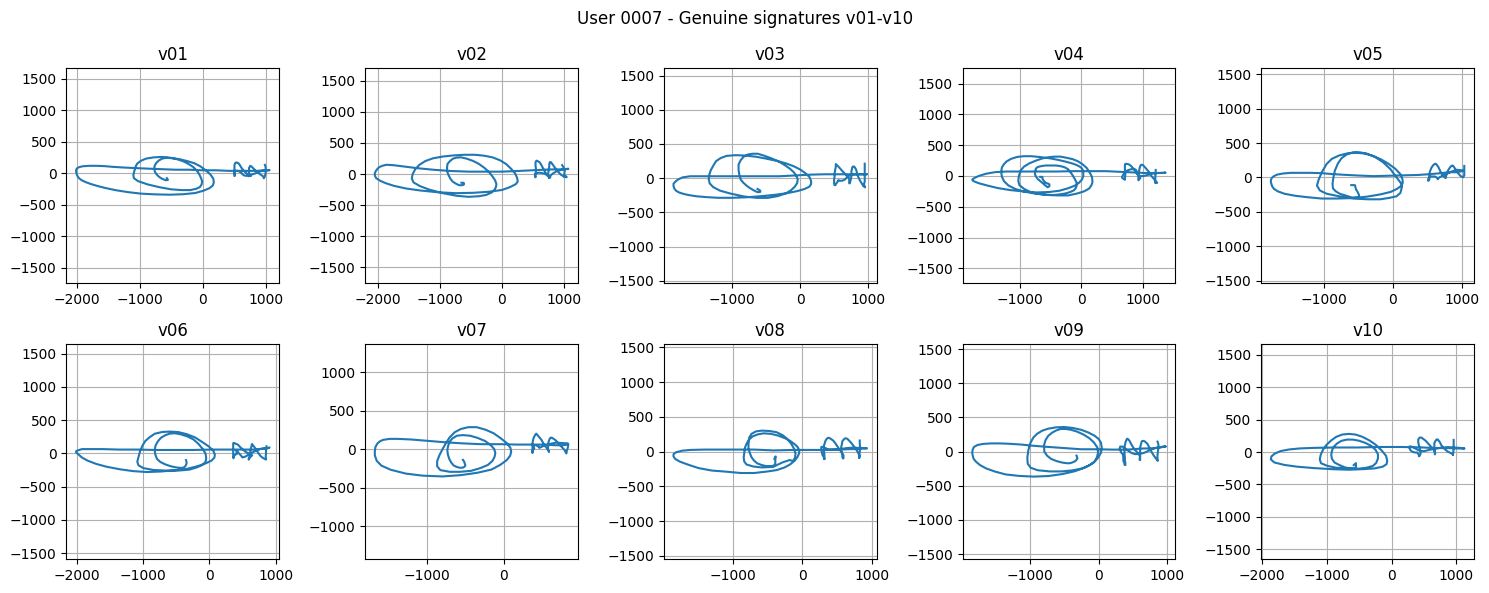

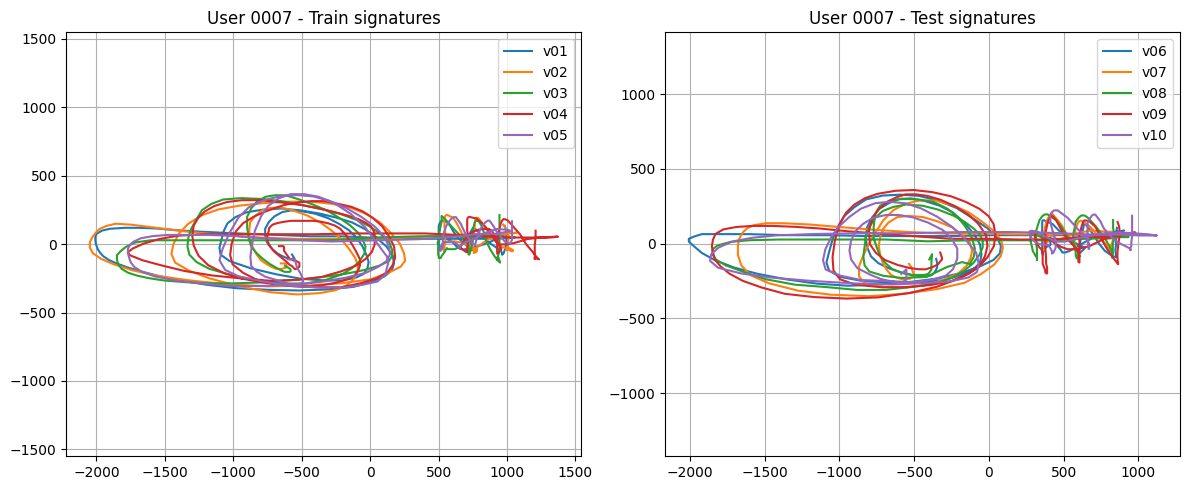

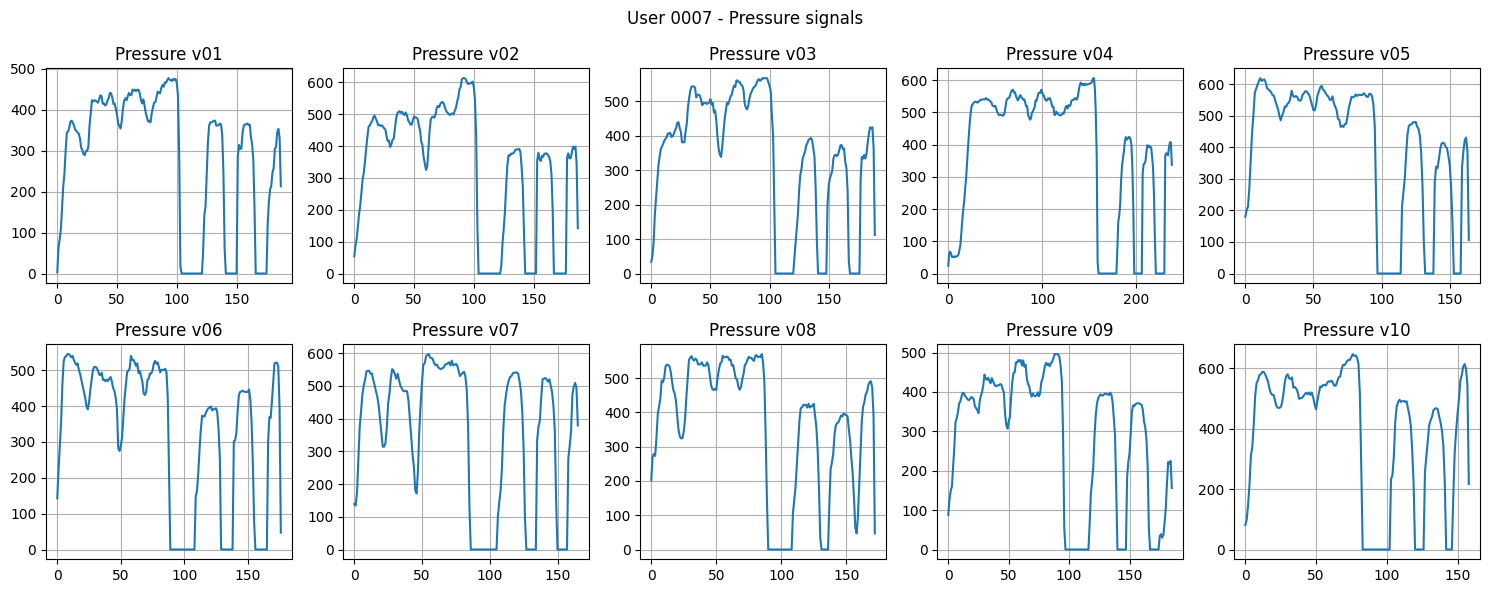

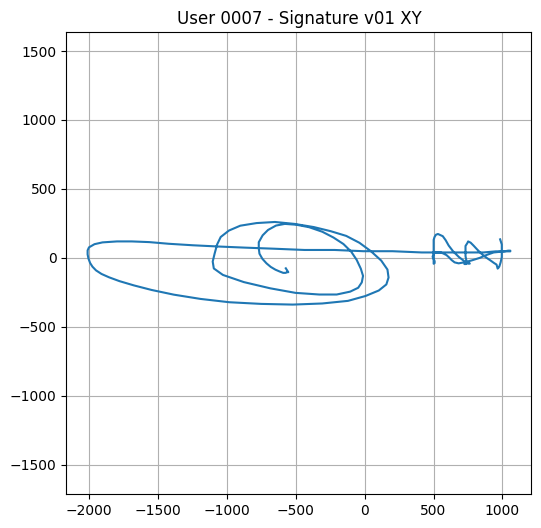

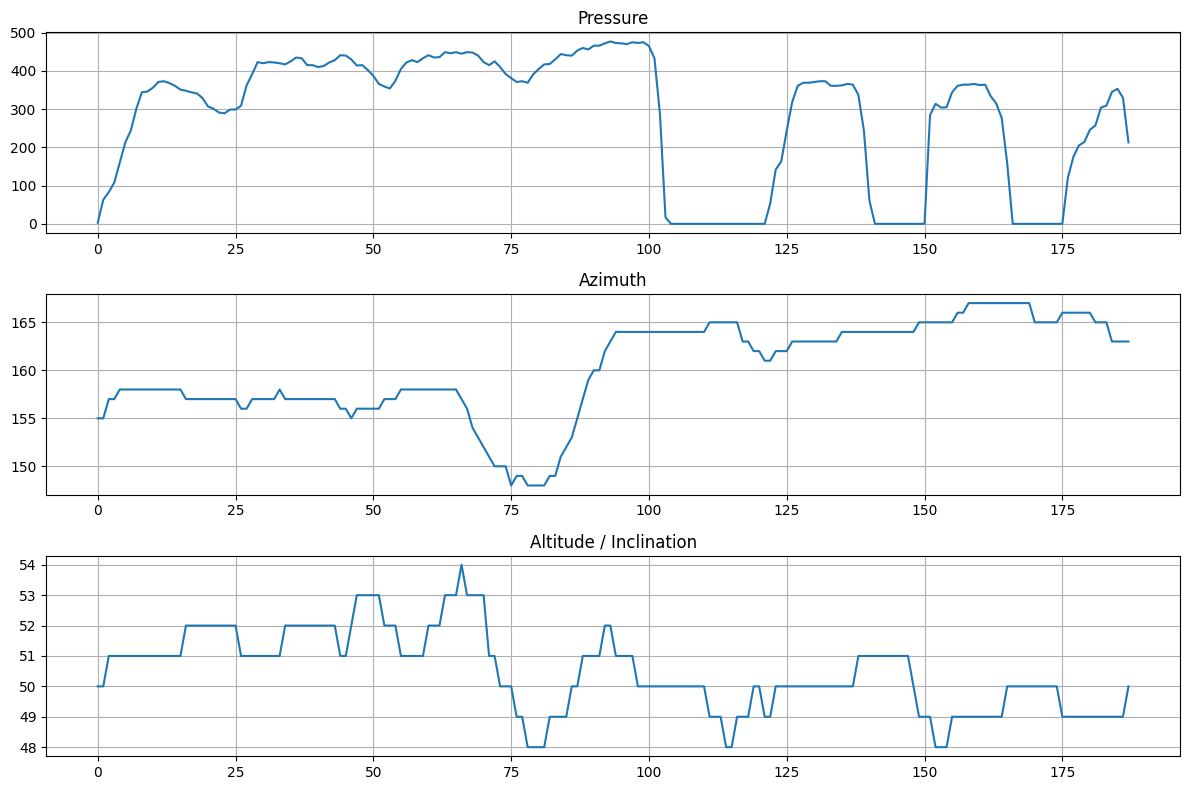

In [ ]:
SINGLE_USER = 7
single_subject_summary(SINGLE_USER)
plot_all_signatures_grid(SINGLE_USER)
plot_train_test_xy(SINGLE_USER)
plot_pressure_grid(SINGLE_USER)
plot_azimuth_altitude_pressure(SINGLE_USER, sig_id=1)

PHASE C: Générer 5 signatures synthétiques

In [ ]:
!pip install torch

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# AUTOENCODER MCYT
# ============================================================

TARGET_LEN = 256
AE_EPOCHS = 100
AE_LR = 5e-4
AE_HIDDEN_DIM = 256
AE_LATENT_DIM = 64
AE_BATCH_SIZE = 2

SINGLE_USER = 0


def resample_sequence(seq, target_len=256):
    old_idx = np.linspace(0, len(seq) - 1, len(seq))
    new_idx = np.linspace(0, len(seq) - 1, target_len)

    out = np.zeros((target_len, seq.shape[1]), dtype=np.float32)

    for i in range(seq.shape[1]):
        out[:, i] = np.interp(new_idx, old_idx, seq[:, i])

    return out


def prepare_mcyt_for_ae(vect, target_len=256):
    """
    vect = signature brute MCYT après traslada_firma
    colonnes : x, y, pressure
    """

    x = vect[:, 0]
    y = vect[:, 1]
    p = vect[:, 2]

    # normalisation par signature
    x = (x - np.mean(x)) / (np.std(x) + 1e-8)
    y = (y - np.mean(y)) / (np.std(y) + 1e-8)
    p = (p - np.mean(p)) / (np.std(p) + 1e-8)

    seq = np.stack([x, y, p], axis=1).astype(np.float32)

    return resample_sequence(seq, target_len)


def load_user_train_sequences_for_ae(user_id):
    sequences = []

    for sig_id in TRAIN_SIGNATURES:  # v01-v05
        vect = load_raw_signature(user_id, "v", sig_id)
        seq = prepare_mcyt_for_ae(vect, TARGET_LEN)
        sequences.append(seq)

    return np.stack(sequences, axis=0)


class SignatureDataset(Dataset):
    def __init__(self, sequences):
        self.data = torch.tensor(sequences, dtype=torch.float32)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


class SeqAutoencoder(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=256, latent_dim=64):
        super().__init__()

        self.encoder = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.to_latent = nn.Linear(hidden_dim, latent_dim)
        self.from_latent = nn.Linear(latent_dim, hidden_dim)

        self.decoder = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.output_layer = nn.Linear(hidden_dim, input_dim)

        self.hidden_dim = hidden_dim
        self.input_dim = input_dim

    def encode(self, x):
        _, h = self.encoder(x)
        h = h[-1]
        z = self.to_latent(h)
        return z

    def decode(self, z, seq_len, teacher_forcing_input=None):
        batch_size = z.size(0)

        h0 = self.from_latent(z).unsqueeze(0)

        if teacher_forcing_input is None:
            decoder_input = torch.zeros(batch_size, seq_len, self.input_dim).to(z.device)
        else:
            decoder_input = teacher_forcing_input

        out, _ = self.decoder(decoder_input, h0)
        recon = self.output_layer(out)

        return recon

    def forward(self, x):
        z = self.encode(x)

        decoder_in = torch.zeros_like(x)
        decoder_in[:, 1:, :] = x[:, :-1, :]

        recon = self.decode(z, x.size(1), decoder_in)

        return recon, z


def train_ae_for_user(user_id):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    sequences = load_user_train_sequences_for_ae(user_id)
    dataset = SignatureDataset(sequences)
    loader = DataLoader(dataset, batch_size=AE_BATCH_SIZE, shuffle=True)

    model = SeqAutoencoder(
        input_dim=3,
        hidden_dim=AE_HIDDEN_DIM,
        latent_dim=AE_LATENT_DIM
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=AE_LR)
    loss_fn = nn.MSELoss()

    losses = []

    for epoch in range(AE_EPOCHS):
        total_loss = 0

        for batch in loader:
            batch = batch.to(device)

            recon, _ = model(batch)
            loss = loss_fn(recon, batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(loader)
        losses.append(avg_loss)

        if (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch+1}/{AE_EPOCHS} | loss={avg_loss:.6f}")

    plt.figure(figsize=(8, 4))
    plt.plot(losses)
    plt.title(f"AE training loss - user {user_id:04d}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.show()

    return model, sequences, device

In [ ]:
# Génération synthétiques

def generate_synthetic_signature(model, base_seq, device, noise_std=0.01):
    model.eval()

    sample = torch.tensor(base_seq, dtype=torch.float32).unsqueeze(0).to(device)

    with torch.no_grad():
        z = model.encode(sample)
        z_noisy = z + noise_std * torch.randn_like(z)

        decoder_in = torch.zeros_like(sample)
        decoder_in[:, 1:, :] = sample[:, :-1, :]

        gen = model.decode(
            z_noisy,
            seq_len=sample.size(1),
            teacher_forcing_input=decoder_in
        )

    return gen.squeeze(0).cpu().numpy()


def plot_synthetic_results(original_seq, synthetic_seq, title="Synthetic signature"):
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(original_seq[:, 0], -original_seq[:, 1])
    plt.title("Original")
    plt.axis("equal")
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(synthetic_seq[:, 0], -synthetic_seq[:, 1])
    plt.title(title)
    plt.axis("equal")
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 3))
    plt.plot(original_seq[:, 2], label="Original pressure")
    plt.plot(synthetic_seq[:, 2], label="Synthetic pressure")
    plt.title("Pressure comparison")
    plt.legend()
    plt.grid(True)
    plt.show()

Epoch 50/150 | loss=0.021495
Epoch 100/150 | loss=0.011766
Epoch 150/150 | loss=0.008358


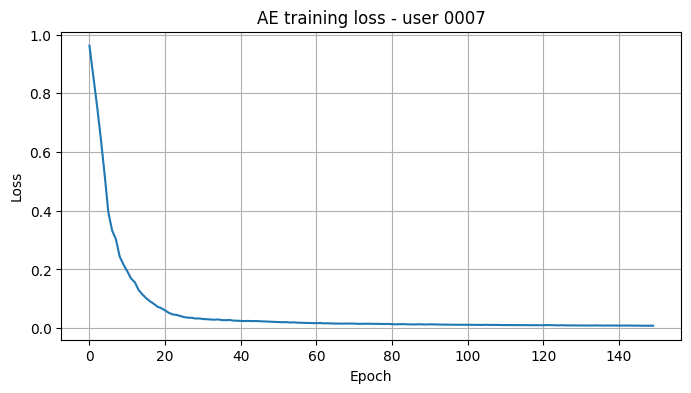

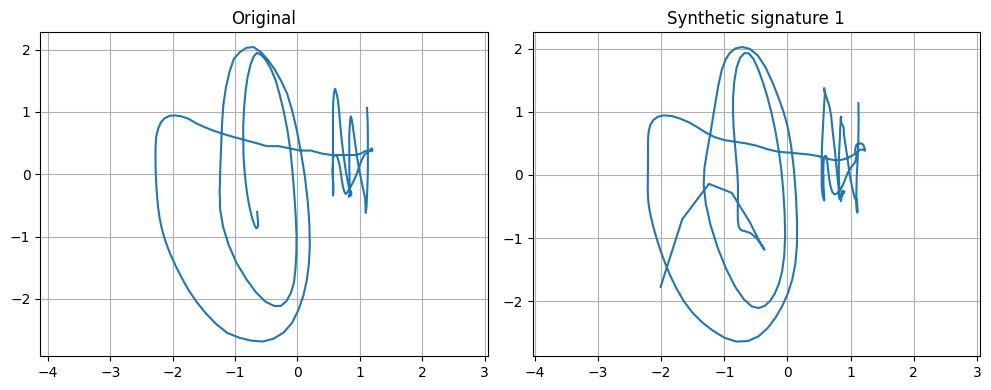

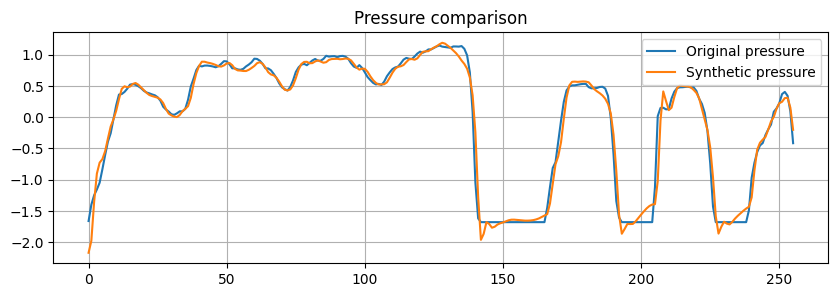

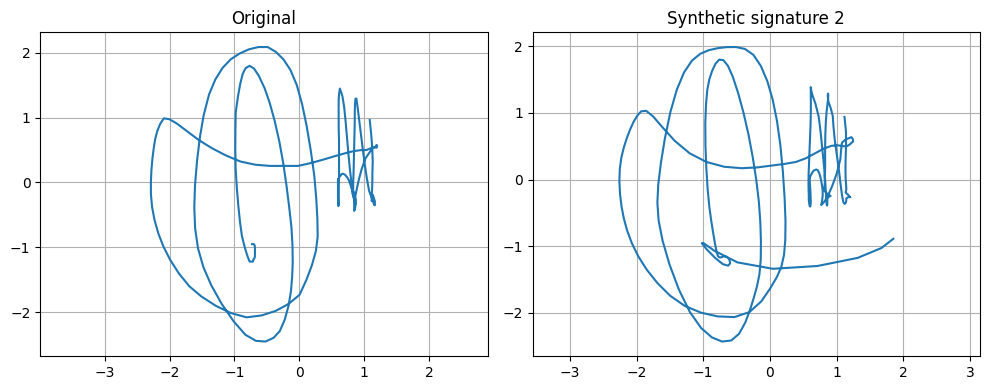

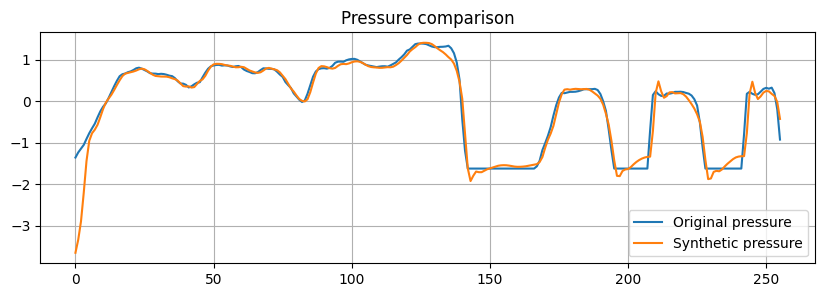

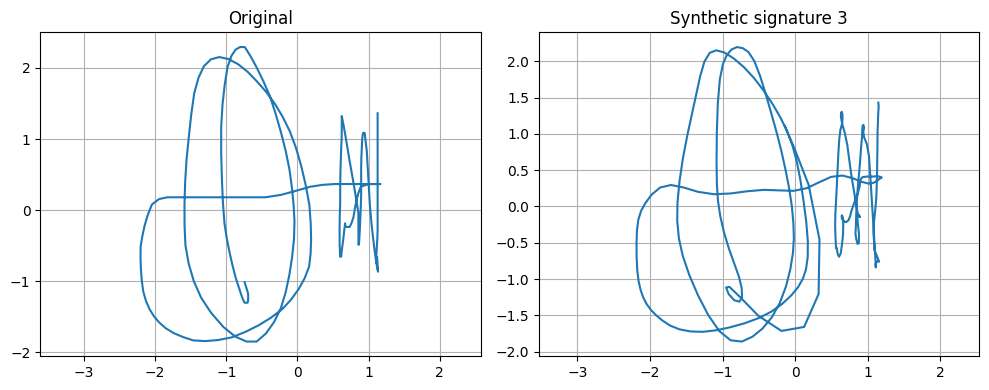

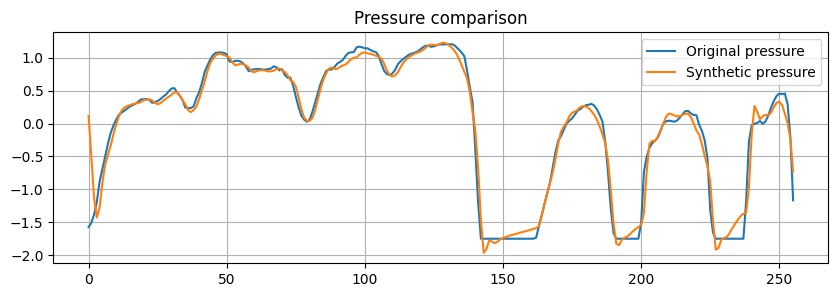

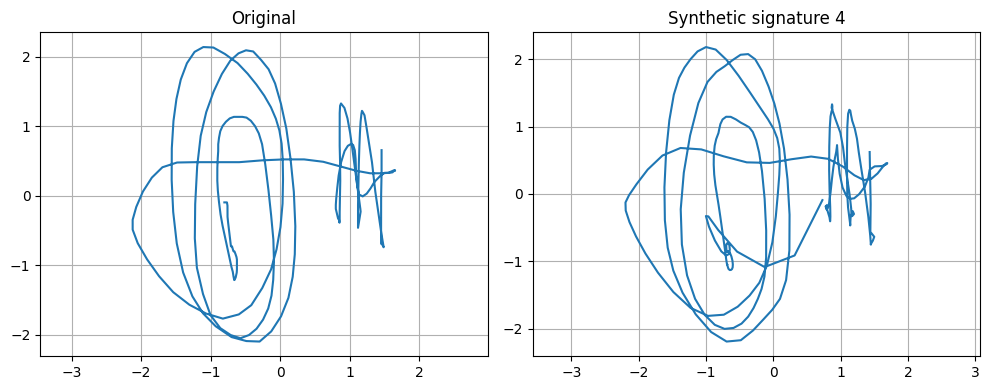

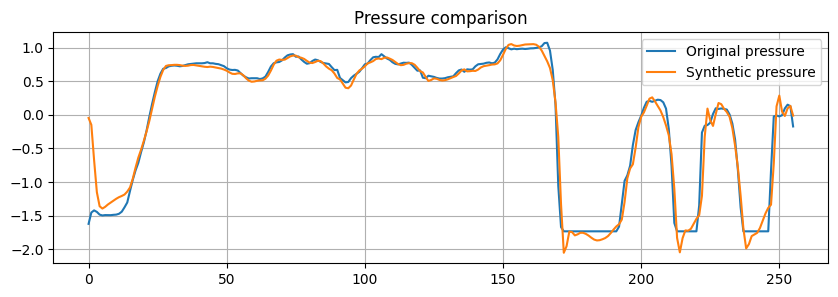

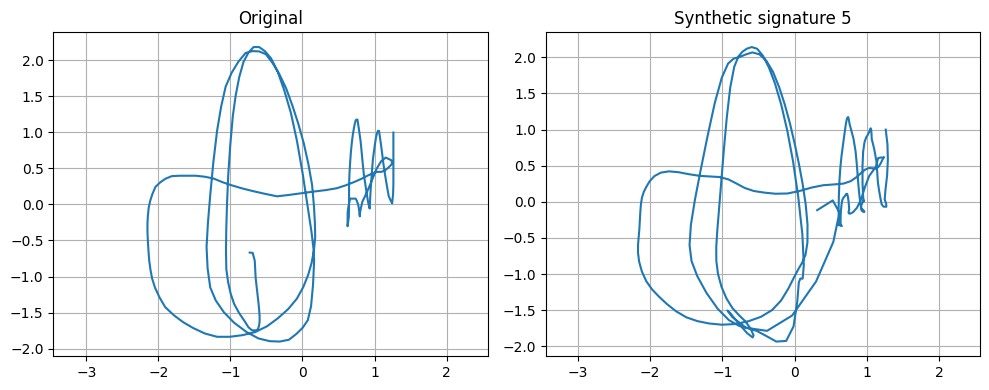

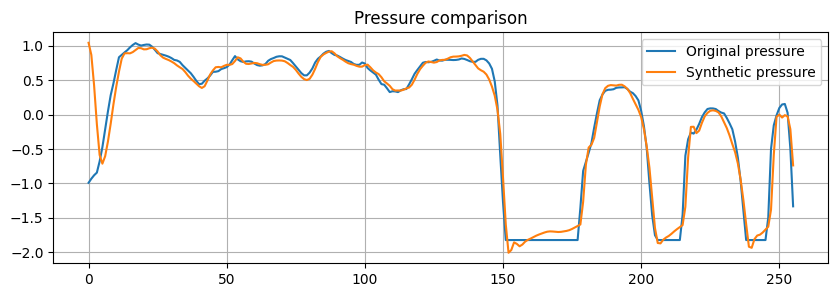

In [ ]:
SINGLE_USER = 7
model_ae, train_sequences, device = train_ae_for_user(SINGLE_USER)

synthetic_signatures = []

for i in range(5):
    base_seq = train_sequences[i % len(train_sequences)]

    synth = generate_synthetic_signature(
        model=model_ae,
        base_seq=base_seq,
        device=device,
        noise_std=3
    )

    synthetic_signatures.append(synth)

    plot_synthetic_results(
        base_seq,
        synth,
        title=f"Synthetic signature {i+1}"
    )

Est ce que DTW accepte comme geniune ou forgeries ?

In [ ]:
def synthetic_to_dtw_features(synthetic_seq):
    """
    synthetic_seq = [x, y, pressure]
    On applique featuresdd comme pour MCYT.
    """
    return featuresdd(
        synthetic_seq[:, 0],
        synthetic_seq[:, 1],
        synthetic_seq[:, 2],
        POINT
    )


def test_synthetic_against_user_model(user_id, synthetic_signatures):
    # modèle DTW du user avec v01-v05
    model_sigs = []

    for sig_id in TRAIN_SIGNATURES:
        vectn = load_signature_features(user_id, "v", sig_id)
        model_sigs.append(vectn)

    print(f"===== Synthetic DTW test for user {user_id:04d} =====")

    for i, synth in enumerate(synthetic_signatures):
        synth_feat = synthetic_to_dtw_features(synth)

        d = model_distance(synth_feat, model_sigs)
        score = -d

        print(f"Synthetic #{i+1} | DTW distance = {d:.6f} | score = {score:.6f}")

In [ ]:
test_synthetic_against_user_model(SINGLE_USER, synthetic_signatures)

===== Synthetic DTW test for user 0007 =====
Synthetic #1 | DTW distance = 0.725123 | score = -0.725123
Synthetic #2 | DTW distance = 0.863358 | score = -0.863358
Synthetic #3 | DTW distance = 0.710855 | score = -0.710855
Synthetic #4 | DTW distance = 0.388066 | score = -0.388066
Synthetic #5 | DTW distance = 1.138597 | score = -1.138597


In [ ]:
def plot_synthetic_dtw_scores(user_id, synthetic_signatures):
    # modèles genuine v01-v05
    model_sigs = []

    for sig_id in TRAIN_SIGNATURES:
        vectn = load_signature_features(user_id, "v", sig_id)
        model_sigs.append(vectn)

    synthetic_distances = []

    for synth in synthetic_signatures:
        synth_feat = synthetic_to_dtw_features(synth)

        d = model_distance(synth_feat, model_sigs)

        synthetic_distances.append(d)

    plt.figure(figsize=(10,5))

    plt.bar(
        [f"Synth #{i+1}" for i in range(len(synthetic_distances))],
        synthetic_distances
    )

    plt.ylabel("DTW distance")
    plt.title(f"Synthetic signature DTW distances - User {user_id:04d}")
    plt.grid(axis="y")

    plt.show()

    print("Mean synthetic DTW distance:",
          np.mean(synthetic_distances))

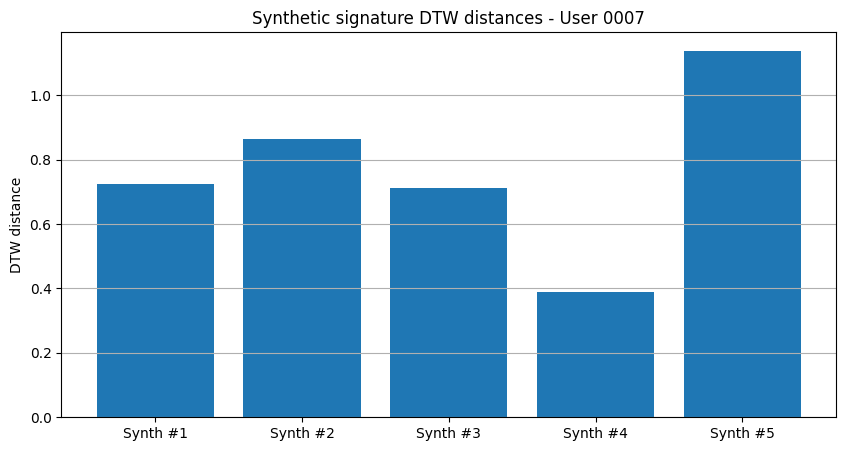

Mean synthetic DTW distance: 0.7651999462451329


In [ ]:
plot_synthetic_dtw_scores(
    SINGLE_USER,
    synthetic_signatures
)

In [ ]:
def plot_genuine_skilled_synthetic_distances(user_id, synthetic_signatures):
    # modèle DTW du user avec v01-v05
    model_sigs = []

    for sig_id in TRAIN_SIGNATURES:
        vectn = load_signature_features(user_id, "v", sig_id)
        model_sigs.append(vectn)

    # 1) Genuine test distances : v06-v10
    genuine_distances = []

    for sig_id in TEST_SIGNATURES:
        vectn = load_signature_features(user_id, "v", sig_id)
        d = model_distance(vectn, model_sigs)
        genuine_distances.append(d)

    # 2) Skilled forgery distances : f00-f24
    skilled_distances = []

    for sig_id in SKILLED_FORGERIES:
        vectn = load_signature_features(user_id, "f", sig_id)
        d = model_distance(vectn, model_sigs)
        skilled_distances.append(d)

    # 3) Synthetic distances
    synthetic_distances = []

    for synth in synthetic_signatures:
        synth_feat = synthetic_to_dtw_features(synth)
        d = model_distance(synth_feat, model_sigs)
        synthetic_distances.append(d)

    # =========================
    # BOXPLOT
    # =========================
    plt.figure(figsize=(9, 6))

    plt.boxplot(
        [genuine_distances, skilled_distances, synthetic_distances],
        labels=["Genuine test", "Skilled forgeries", "Synthetic"],
        showmeans=True
    )

    plt.ylabel("DTW distance")
    plt.title(f"DTW distance comparison - User {user_id:04d}")
    plt.grid(axis="y")
    plt.show()

    # =========================
    # SCATTER + DISTRIBUTION
    # =========================
    plt.figure(figsize=(10, 5))

    x_genuine = np.random.normal(1, 0.04, size=len(genuine_distances))
    x_skilled = np.random.normal(2, 0.04, size=len(skilled_distances))
    x_synth = np.random.normal(3, 0.04, size=len(synthetic_distances))

    plt.scatter(x_genuine, genuine_distances, label="Genuine test")
    plt.scatter(x_skilled, skilled_distances, label="Skilled forgeries")
    plt.scatter(x_synth, synthetic_distances, label="Synthetic")

    plt.xticks([1, 2, 3], ["Genuine test", "Skilled forgeries", "Synthetic"])
    plt.ylabel("DTW distance")
    plt.title(f"Individual DTW distances - User {user_id:04d}")
    plt.grid(axis="y")
    plt.legend()
    plt.show()

    # =========================
    # PRINT SUMMARY
    # =========================
    print(f"===== DTW DISTANCE SUMMARY - User {user_id:04d} =====")

    print("\nGenuine test:")
    print("Distances:", np.round(genuine_distances, 4))
    print("Mean:", round(np.mean(genuine_distances), 4))
    print("Min :", round(np.min(genuine_distances), 4))
    print("Max :", round(np.max(genuine_distances), 4))

    print("\nSkilled forgeries:")
    print("Mean:", round(np.mean(skilled_distances), 4))
    print("Min :", round(np.min(skilled_distances), 4))
    print("Max :", round(np.max(skilled_distances), 4))

    print("\nSynthetic:")
    print("Distances:", np.round(synthetic_distances, 4))
    print("Mean:", round(np.mean(synthetic_distances), 4))
    print("Min :", round(np.min(synthetic_distances), 4))
    print("Max :", round(np.max(synthetic_distances), 4))

    return genuine_distances, skilled_distances, synthetic_distances

/tmp/ipykernel_8640/1598148453.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


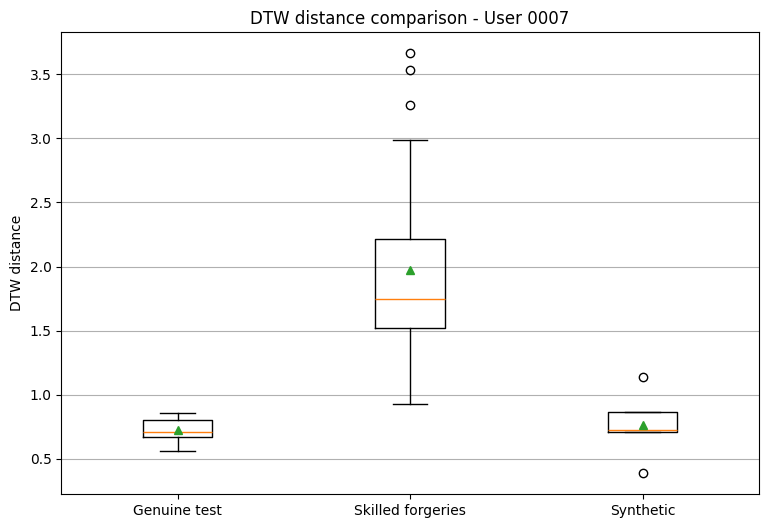

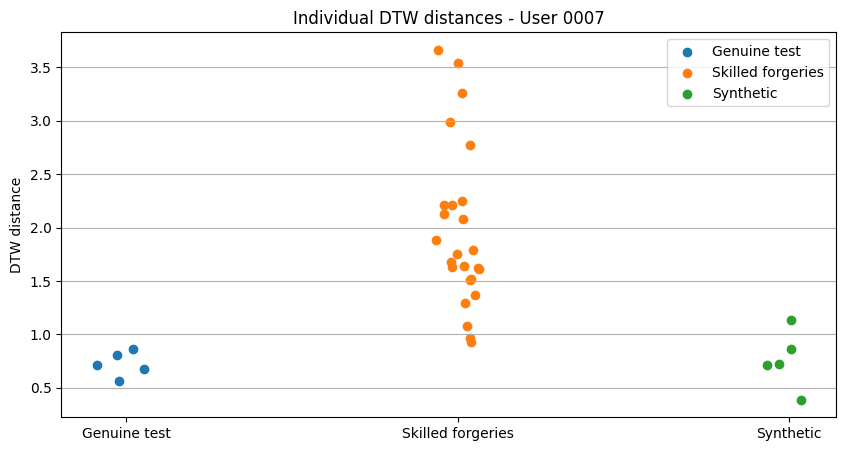

===== DTW DISTANCE SUMMARY - User 0007 =====

Genuine test:
Distances: [0.5638 0.7115 0.8069 0.6733 0.8594]
Mean: 0.723
Min : 0.5638
Max : 0.8594

Skilled forgeries:
Mean: 1.9755
Min : 0.9309
Max : 3.6631

Synthetic:
Distances: [0.7251 0.8634 0.7109 0.3881 1.1386]
Mean: 0.7652
Min : 0.3881
Max : 1.1386


In [ ]:
genuine_d, skilled_d, synthetic_d = plot_genuine_skilled_synthetic_distances(
    SINGLE_USER,
    synthetic_signatures
)

PHASE D: Full dataset + 5 synthetiques pour chaque users

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
SAVE_DIR = "/content/drive/MyDrive/MCYT_PHASE_D"

os.makedirs(SAVE_DIR, exist_ok=True)

print("Directory created:", SAVE_DIR)

Directory created: /content/drive/MyDrive/MCYT_PHASE_D


In [ ]:
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm


# =========================
# PHASE D PARAMETERS
# =========================

FULL_USERS_LIMIT = None      # None = all MCYT users
N_SYNTH_PER_USER = 5
SYNTH_NOISE_STD = 3.0
AE_EPOCHS_FULL = 100         # évite 300 sur tout le dataset
SAVE_RESULTS = True


# =========================
# MIN DCF WITH THRESHOLD
# =========================

def min_dcf_with_threshold(true_scores, impostor_scores, C_miss=1, C_fa=1, P_target=0.5):
    true_scores = np.asarray(true_scores)
    impostor_scores = np.asarray(impostor_scores)

    scores = np.concatenate([true_scores, impostor_scores])
    thresholds = np.sort(scores)

    best_dcf = float("inf")
    best_th = None
    best_pmiss = None
    best_pfa = None

    for th in thresholds:
        p_miss = np.mean(true_scores < th)
        p_fa = np.mean(impostor_scores >= th)

        dcf = C_miss * P_target * p_miss + C_fa * (1 - P_target) * p_fa

        if dcf < best_dcf:
            best_dcf = dcf
            best_th = th
            best_pmiss = p_miss
            best_pfa = p_fa

    return best_dcf, best_th, best_pmiss, best_pfa


def metrics_against_genuine(true_scores, impostor_scores):
    P_miss, P_fa = compute_det(true_scores, impostor_scores)
    eer, eer_miss, eer_fa = compute_eer(P_miss, P_fa)
    dcf, th, pmiss, pfa = min_dcf_with_threshold(true_scores, impostor_scores)

    return {
        "EER": eer,
        "EER_%": eer * 100,
        "minDCF": dcf,
        "minDCF_%": dcf * 100,
        "threshold": th,
        "Pmiss@DCF": pmiss,
        "Pfa@DCF": pfa,
    }


# =========================
# AE TRAIN WITHOUT PLOT
# =========================

def train_ae_for_user_quiet(user_id, epochs=100):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    sequences = load_user_train_sequences_for_ae(user_id)
    dataset = SignatureDataset(sequences)
    loader = DataLoader(dataset, batch_size=AE_BATCH_SIZE, shuffle=True)

    model = SeqAutoencoder(
        input_dim=3,
        hidden_dim=AE_HIDDEN_DIM,
        latent_dim=AE_LATENT_DIM
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=AE_LR)
    loss_fn = nn.MSELoss()

    losses = []

    for epoch in range(epochs):
        total_loss = 0

        for batch in loader:
            batch = batch.to(device)

            recon, _ = model(batch)
            loss = loss_fn(recon, batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        losses.append(total_loss / len(loader))

    return model, sequences, device, losses


# =========================
# FULL PHASE D EXPERIMENT
# =========================

def run_phase_d_full_dataset():
    users = get_mcyt_users(FULL_USERS_LIMIT)

    all_true_scores = []
    all_random_scores = []
    all_skilled_scores = []
    all_synthetic_scores = []

    genuine_distances = []
    random_distances = []
    skilled_distances = []
    synthetic_distances = []

    rows = []

    print("===== PHASE D - FULL DATASET SYNTHETIC EXPERIMENT =====")
    print("Users:", len(users))
    print("Synthetic per user:", N_SYNTH_PER_USER)
    print("Noise std:", SYNTH_NOISE_STD)
    print("AE epochs per user:", AE_EPOCHS_FULL)



    import os

    already_done_users = set()
    checkpoint_path = f"{SAVE_DIR}/phase_d_checkpoint.csv"

    if os.path.exists(checkpoint_path):
        checkpoint_df = pd.read_csv(checkpoint_path)
        already_done_users = set(checkpoint_df["user"].tolist())
        rows = checkpoint_df.to_dict("records")
        print("Already completed users:", len(already_done_users))

    for user_id in tqdm(users):

        # =========================
        # SKIP ALREADY DONE USERS
        # =========================
        if user_id in already_done_users:
            print(f"Skipping user {user_id}")
            continue

        # -------------------------
        # 1) DTW model v01-v05
        # -------------------------
        model_sigs = []

        for sig_id in TRAIN_SIGNATURES:
            feat = load_signature_features(user_id, "v", sig_id)
            model_sigs.append(feat)

        # -------------------------
        # 2) Genuine test v06-v10
        # -------------------------
        user_genuine_dist = []

        for sig_id in TEST_SIGNATURES:
            feat = load_signature_features(user_id, "v", sig_id)
            d = model_distance(feat, model_sigs)

            user_genuine_dist.append(d)
            genuine_distances.append(d)
            all_true_scores.append(-d)

        # -------------------------
        # 3) Random forgeries
        # Ici : signatures genuine d'autres users
        # -------------------------
        for other_user in users:
            if other_user == user_id:
                continue

            for sig_id in TEST_SIGNATURES:
                feat = load_signature_features(other_user, "v", sig_id)
                d = model_distance(feat, model_sigs)

                random_distances.append(d)
                all_random_scores.append(-d)

        # -------------------------
        # 4) Skilled forgeries f00-f24
        # -------------------------
        user_skilled_dist = []

        for sig_id in SKILLED_FORGERIES:
            feat = load_signature_features(user_id, "f", sig_id)
            d = model_distance(feat, model_sigs)

            user_skilled_dist.append(d)
            skilled_distances.append(d)
            all_skilled_scores.append(-d)

        # -------------------------
        # 5) Train AE for this user
        # -------------------------
        ae_model, train_sequences, device, losses = train_ae_for_user_quiet(
            user_id,
            epochs=AE_EPOCHS_FULL
        )

        # -------------------------
        # 6) Generate synthetic signatures
        # -------------------------
        user_synthetic_dist = []

        for i in range(N_SYNTH_PER_USER):
            base_seq = train_sequences[i % len(train_sequences)]

            synth = generate_synthetic_signature(
                model=ae_model,
                base_seq=base_seq,
                device=device,
                noise_std=SYNTH_NOISE_STD
            )

            synth_feat = synthetic_to_dtw_features(synth)
            d = model_distance(synth_feat, model_sigs)

            user_synthetic_dist.append(d)
            synthetic_distances.append(d)
            all_synthetic_scores.append(-d)

        rows.append({
            "user": user_id,
            "genuine_mean_dist": np.mean(user_genuine_dist),
            "skilled_mean_dist": np.mean(user_skilled_dist),
            "synthetic_mean_dist": np.mean(user_synthetic_dist),
            "ae_final_loss": losses[-1],
        })

        # =========================
        # CHECKPOINT SAVE
        # =========================

        checkpoint_df = pd.DataFrame(rows)

        checkpoint_df.to_csv(
            f"{SAVE_DIR}/phase_d_checkpoint.csv",
            index=False
        )

        np.savez(
            f"{SAVE_DIR}/phase_d_partial_scores.npz",
            true_scores=np.array(all_true_scores),
            random_scores=np.array(all_random_scores),
            skilled_scores=np.array(all_skilled_scores),
            synthetic_scores=np.array(all_synthetic_scores),
        )

        print(f"Checkpoint saved after user {user_id}")

    # =========================
    # GLOBAL METRICS
    # =========================

    all_true_scores = np.array(all_true_scores)
    all_random_scores = np.array(all_random_scores)
    all_skilled_scores = np.array(all_skilled_scores)
    all_synthetic_scores = np.array(all_synthetic_scores)

    random_metrics = metrics_against_genuine(all_true_scores, all_random_scores)
    skilled_metrics = metrics_against_genuine(all_true_scores, all_skilled_scores)
    synthetic_metrics = metrics_against_genuine(all_true_scores, all_synthetic_scores)

    # Threshold basé sur genuine vs skilled
    skilled_threshold = skilled_metrics["threshold"]

    synthetic_acceptance_rate = np.mean(all_synthetic_scores >= skilled_threshold)
    skilled_false_acceptance_rate = np.mean(all_skilled_scores >= skilled_threshold)

    # =========================
    # PRINT RESULTS
    # =========================

    print("\n===== GLOBAL DISTANCE SUMMARY =====")
    print(f"Genuine mean   : {np.mean(genuine_distances):.4f}")
    print(f"Random mean    : {np.mean(random_distances):.4f}")
    print(f"Skilled mean   : {np.mean(skilled_distances):.4f}")
    print(f"Synthetic mean : {np.mean(synthetic_distances):.4f}")

    print("\n===== RANDOM FORGERIES =====")
    for k, v in random_metrics.items():
        print(f"{k}: {v:.6f}")

    print("\n===== SKILLED FORGERIES =====")
    for k, v in skilled_metrics.items():
        print(f"{k}: {v:.6f}")

    print("\n===== SYNTHETIC SIGNATURES AS FORGERIES =====")
    for k, v in synthetic_metrics.items():
        print(f"{k}: {v:.6f}")

    print("\n===== ACCEPTANCE ANALYSIS =====")
    print(f"Threshold from skilled minDCF: {skilled_threshold:.6f}")
    print(f"Skilled FAR at this threshold: {skilled_false_acceptance_rate * 100:.2f}%")
    print(f"Synthetic acceptance rate    : {synthetic_acceptance_rate * 100:.2f}%")

    # =========================
    # PLOTS
    # =========================

    plt.figure(figsize=(10, 6))
    plt.boxplot(
        [genuine_distances, skilled_distances, synthetic_distances],
        labels=["Genuine", "Skilled forgeries", "Synthetic"],
        showmeans=True
    )
    plt.ylabel("DTW distance")
    plt.title("Full MCYT - DTW distance comparison")
    plt.grid(axis="y")
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.hist(genuine_distances, bins=40, alpha=0.5, label="Genuine")
    plt.hist(skilled_distances, bins=40, alpha=0.5, label="Skilled")
    plt.hist(synthetic_distances, bins=40, alpha=0.5, label="Synthetic")
    plt.xlabel("DTW distance")
    plt.ylabel("Count")
    plt.title("Full MCYT - Distance distributions")
    plt.legend()
    plt.grid(True)
    plt.show()

    # =========================
    # SAVE
    # =========================

    df = pd.DataFrame(rows)

    if SAVE_RESULTS:
        df.to_csv("phase_d_user_summary.csv", index=False)

        np.savez(
            "phase_d_scores_distances.npz",
            true_scores=all_true_scores,
            random_scores=all_random_scores,
            skilled_scores=all_skilled_scores,
            synthetic_scores=all_synthetic_scores,
            genuine_distances=np.array(genuine_distances),
            random_distances=np.array(random_distances),
            skilled_distances=np.array(skilled_distances),
            synthetic_distances=np.array(synthetic_distances),
        )

        print("\nSaved:")
        print("- phase_d_user_summary.csv")
        print("- phase_d_scores_distances.npz")

    return {
        "random_metrics": random_metrics,
        "skilled_metrics": skilled_metrics,
        "synthetic_metrics": synthetic_metrics,
        "synthetic_acceptance_rate": synthetic_acceptance_rate,
        "df_summary": df,
        "genuine_distances": genuine_distances,
        "skilled_distances": skilled_distances,
        "synthetic_distances": synthetic_distances,
    }

===== PHASE D - FULL DATASET SYNTHETIC EXPERIMENT =====
Users: 10
Synthetic per user: 5
Noise std: 3.0
AE epochs per user: 100


 10%|█         | 1/10 [01:57<17:37, 117.54s/it]

Checkpoint saved after user 0


 20%|██        | 2/10 [03:59<16:00, 120.11s/it]

Checkpoint saved after user 1


...

 90%|█████████ | 9/10 [19:31<01:56, 116.82s/it]

Checkpoint saved after user 8


100%|██████████| 10/10 [22:40<00:00, 136.09s/it]

Checkpoint saved after user 9

===== GLOBAL DISTANCE SUMMARY =====
Genuine mean   : 0.9133
Random mean    : 3.8294
Skilled mean   : 3.1192
Synthetic mean : 1.4676

===== RANDOM FORGERIES =====
EER: 0.000000
EER_%: 0.000000
minDCF: 0.000000
minDCF_%: 0.000000
threshold: -1.840030
Pmiss@DCF: 0.000000
Pfa@DCF: 0.000000

===== SKILLED FORGERIES =====
EER: 0.036000
EER_%: 3.600000
minDCF: 0.026000
minDCF_%: 2.600000
threshold: -1.540312
Pmiss@DCF: 0.020000
Pfa@DCF: 0.032000

===== SYNTHETIC SIGNATURES AS FORGERIES =====
EER: 0.360000
EER_%: 36.000000
minDCF: 0.280000
minDCF_%: 28.000000
threshold: -1.194809
Pmiss@DCF: 0.120000
Pfa@DCF: 0.440000

===== ACCEPTANCE ANALYSIS =====
Threshold from skilled minDCF: -1.540312
Skilled FAR at this threshold: 3.20%
Synthetic acceptance rate    : 76.00%



/tmp/ipykernel_3517/3405151524.py:315: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


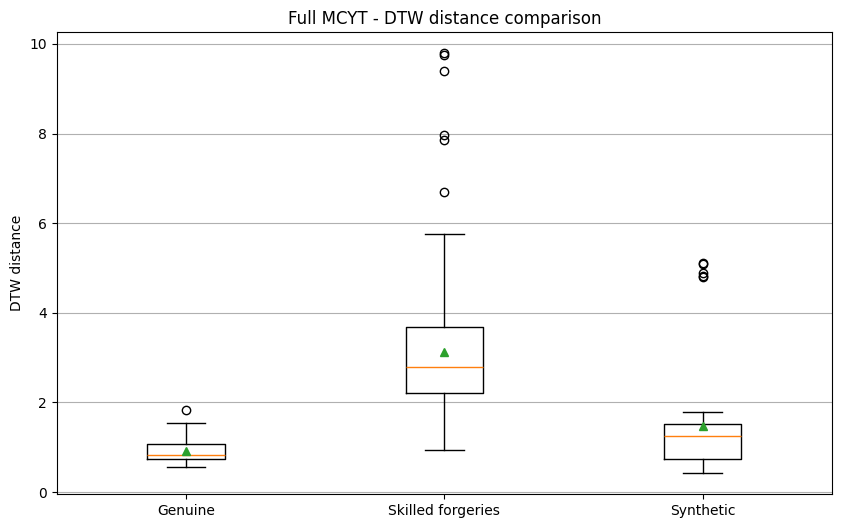

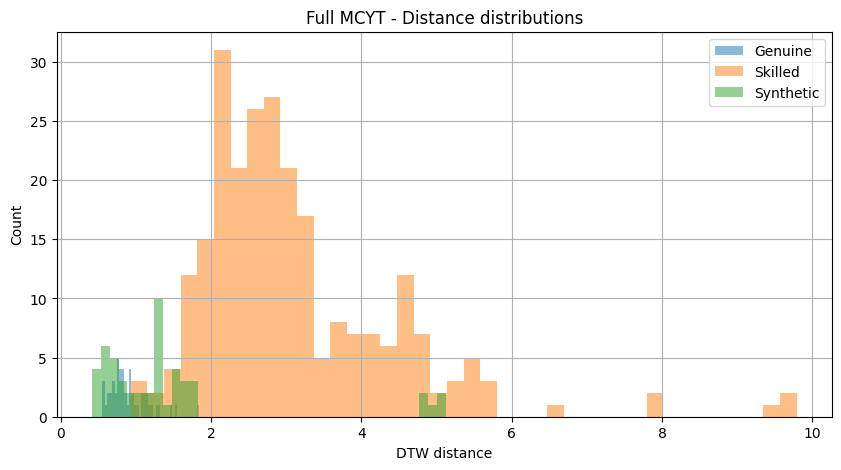


Saved:
- phase_d_user_summary.csv
- phase_d_scores_distances.npz


In [ ]:
FULL_USERS_LIMIT = 10
phase_d_results = run_phase_d_full_dataset()

===== PHASE D - FULL DATASET SYNTHETIC EXPERIMENT =====
Users: 330
Synthetic per user: 5
Noise std: 3.0
AE epochs per user: 100
Already completed users: 135


  0%|          | 0/330 [00:00<?, ?it/s]

Skipping user 0
Skipping user 1
Skipping user 2
Skipping user 3
Skipping user 4
Skipping user 5
Skipping user 6
Skipping user 7
Skipping user 8
Skipping user 9
Skipping user 10
Skipping user 11
Skipping user 12
Skipping user 13
Skipping user 14
Skipping user 15
Skipping user 16
Skipping user 17
Skipping user 18
Skipping user 19
Skipping user 20
Skipping user 21
Skipping user 22
Skipping user 23
Skipping user 24
Skipping user 25
Skipping user 26
Skipping user 27
Skipping user 28
Skipping user 29
Skipping user 30
Skipping user 31
Skipping user 32
Skipping user 33
Skipping user 34
Skipping user 35
Skipping user 36
Skipping user 37
Skipping user 38
Skipping user 39
Skipping user 40
Skipping user 41
Skipping user 42
Skipping user 43
Skipping user 44
Skipping user 45
Skipping user 46
Skipping user 47
Skipping user 48
Skipping user 49
Skipping user 50
Skipping user 51
Skipping user 52
Skipping user 53
Skipping user 54
Skipping user 55
Skipping user 56
Skipping user 57
Skipping user 58
Skippin

 41%|████      | 136/330 [02:56<04:11,  1.29s/it]

Checkpoint saved after user 135


...

Checkpoint saved after user 433


100%|██████████| 330/330 [10:34:46<00:00, 115.41s/it]

Checkpoint saved after user 434



===== GLOBAL DISTANCE SUMMARY =====
Genuine mean   : 0.8703
Random mean    : 3.6927
Skilled mean   : 3.3052
Synthetic mean : 1.4694

===== RANDOM FORGERIES =====
EER: 0.008205
EER_%: 0.820513
minDCF: 0.005943
minDCF_%: 0.594342
threshold: -1.818435
Pmiss@DCF: 0.010256
Pfa@DCF: 0.001630

===== SKILLED FORGERIES =====
EER: 0.043077
EER_%: 4.307692
minDCF: 0.040821
minDCF_%: 4.082051
threshold: -1.462325
Pmiss@DCF: 0.043077
Pfa@DCF: 0.038564

===== SYNTHETIC SIGNATURES AS FORGERIES =====
EER: 0.251282
EER_%: 25.128205
minDCF: 0.231795
minDCF_%: 23.179487
threshold: -1.134941
Pmiss@DCF: 0.143590
Pfa@DCF: 0.320000

===== ACCEPTANCE ANALYSIS =====
Threshold from skilled minDCF: -1.462325
Skilled FAR at this threshold: 3.86%
Synthetic acceptance rate    : 52.10%


/tmp/ipykernel_20239/3405151524.py:315: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


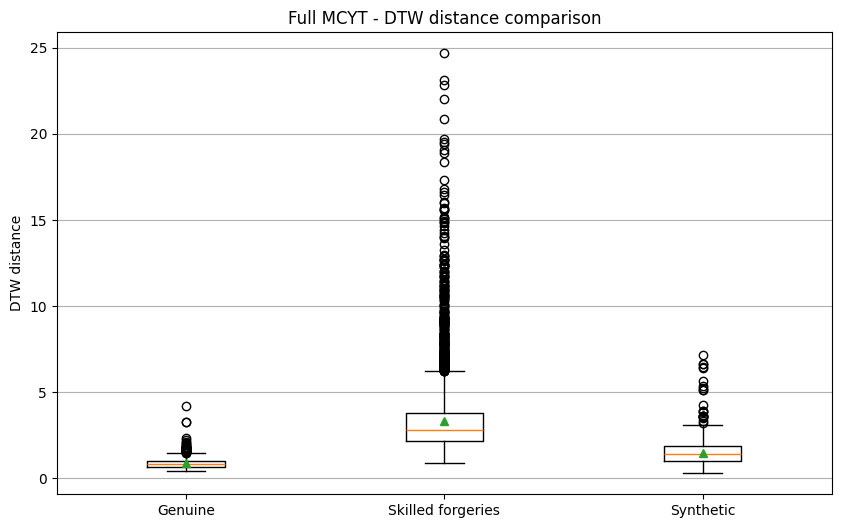

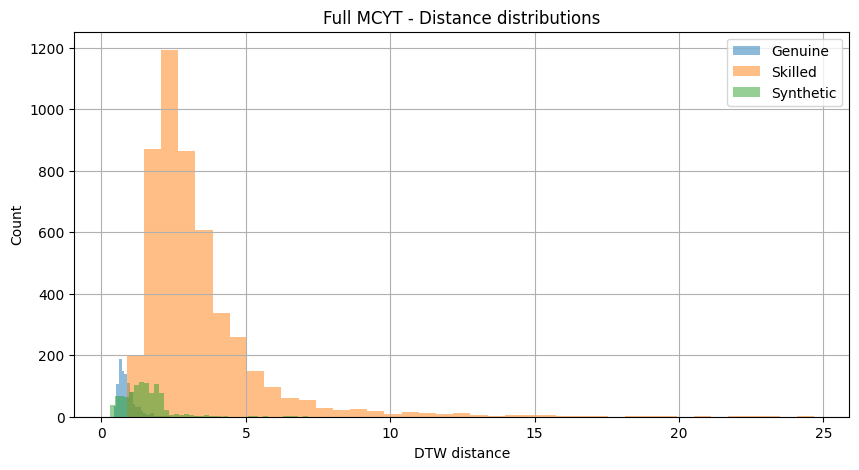


Saved:
- phase_d_user_summary.csv
- phase_d_scores_distances.npz


In [ ]:
FULL_USERS_LIMIT = None
phase_d_results = run_phase_d_full_dataset()

COMPARAISON D'EXPERIENCES

Experience 1: 1 geniune signature

In [ ]:
def run_experiment_1_genuine():
    users = get_mcyt_users(None)

    print("===== EXPERIMENT 1: 1 GENUINE TRAINING SIGNATURE =====")
    print("Training: v01 only")
    print("Testing: v06-v10 + random forgeries + skilled forgeries")
    print("Users:", len(users))

    train_signature_ids = [1]

    mat_d = {}
    true_speaker_scores = []
    impostor_scores = []
    skilled_scores = []

    # =========================
    # Build models with v01 only
    # =========================
    print("\nBuilding models with v01...")
    modelos = {}

    for user_id in tqdm(users):
        modelos[user_id] = []

        for sig_id in train_signature_ids:
            feat = load_signature_features(user_id, "v", sig_id)
            modelos[user_id].append(feat)

    # =========================
    # Genuine + random distances
    # =========================
    print("\nComputing genuine and random forgery distances...")

    correct = 0
    total = 0

    for true_user in tqdm(users):
        mat_d[true_user] = {}

        for candidate_user in users:
            mat_d[true_user][candidate_user] = []

        for sig_id in TEST_SIGNATURES:  # v06-v10
            test_feat = load_signature_features(true_user, "v", sig_id)

            distances = []

            for candidate_user in users:
                d = model_distance(test_feat, modelos[candidate_user])

                mat_d[true_user][candidate_user].append(d)
                distances.append(d)

                score = -d

                if candidate_user == true_user:
                    true_speaker_scores.append(score)
                else:
                    impostor_scores.append(score)

            predicted_user = users[int(np.argmin(distances))]

            if predicted_user == true_user:
                correct += 1

            total += 1

    id_rate = 100 * correct / total

    # =========================
    # Skilled forgeries
    # =========================
    print("\nComputing skilled forgery distances...")

    for user_id in tqdm(users):
        for sig_id in SKILLED_FORGERIES:  # f00-f24
            fake_feat = load_signature_features(user_id, "f", sig_id)

            d = model_distance(fake_feat, modelos[user_id])
            skilled_scores.append(-d)

    # =========================
    # Metrics
    # =========================
    true_speaker_scores = np.array(true_speaker_scores)
    impostor_scores = np.array(impostor_scores)
    skilled_scores = np.array(skilled_scores)

    random_metrics = metrics_against_genuine(
        true_speaker_scores,
        impostor_scores
    )

    skilled_metrics = metrics_against_genuine(
        true_speaker_scores,
        skilled_scores
    )

    # =========================
    # Results
    # =========================
    print("\n===== EXPERIMENT 1 RESULTS =====")
    print(f"Training signatures per user: 1 genuine (v01)")
    print(f"ID rate: {id_rate:.4f}%")

    print("\nRandom forgeries")
    for k, v in random_metrics.items():
        print(f"{k}: {v:.6f}")

    print("\nSkilled forgeries")
    for k, v in skilled_metrics.items():
        print(f"{k}: {v:.6f}")

    return {
        "setup": "1 genuine",
        "id_rate": id_rate,
        "random_metrics": random_metrics,
        "skilled_metrics": skilled_metrics,
        "true_scores": true_speaker_scores,
        "random_scores": impostor_scores,
        "skilled_scores": skilled_scores,
    }

In [ ]:
exp1_results = run_experiment_1_genuine()

===== EXPERIMENT 1: 1 GENUINE TRAINING SIGNATURE =====
Training: v01 only
Testing: v06-v10 + random forgeries + skilled forgeries
Users: 330

Building models with v01...


100%|██████████| 330/330 [00:07<00:00, 42.82it/s]



Computing genuine and random forgery distances...


100%|██████████| 330/330 [22:03<00:00,  4.01s/it]



Computing skilled forgery distances...


100%|██████████| 330/330 [04:43<00:00,  1.17it/s]



===== EXPERIMENT 1 RESULTS =====
Training signatures per user: 1 genuine (v01)
ID rate: 97.7576%

Random forgeries
EER: 0.015905
EER_%: 1.590495
minDCF: 0.013729
minDCF_%: 1.372939
threshold: -2.032057
Pmiss@DCF: 0.020606
Pfa@DCF: 0.006853

Skilled forgeries
EER: 0.058788
EER_%: 5.878788
minDCF: 0.056727
minDCF_%: 5.672727
threshold: -1.635224
Pmiss@DCF: 0.063636
Pfa@DCF: 0.049818


Experience 2: 5 geniune (c'est la baseline: la phase A)

Experience 3: 1geniune + 4synthe

In [ ]:
EXP3_SAVE_DIR = "/content/drive/MyDrive/MCYT_EXP3_SYNTH"
os.makedirs(EXP3_SAVE_DIR, exist_ok=True)

In [ ]:
def run_experiment_3_1_genuine_plus_4_synthetic():
    users = get_mcyt_users(None)

    print("===== EXPERIMENT 3: 1 GENUINE + 4 SYNTHETIC TRAINING SIGNATURES =====")
    print("Training: v01 + 4 synthetic signatures generated from v01")
    print("Testing: v06-v10 + random forgeries + skilled forgeries")
    print("Users:", len(users))

    N_SYNTH_TRAIN = 4
    SYNTH_NOISE_STD_EXP3 = 3.0
    AE_EPOCHS_EXP3 = 100

    modelos = {}

    true_speaker_scores = []
    impostor_scores = []
    skilled_scores = []

    correct = 0
    total = 0

    # =========================
    # 1) Build models
    # =========================
    print("\nBuilding models with v01 + 4 synthetic signatures...")

    for user_id in tqdm(users):

        # -------------------------
        # Real v01
        # -------------------------

        real_v01_feat = load_signature_features(
            user_id,
            "v",
            1
        )

        synth_file = (
            f"{EXP3_SAVE_DIR}/"
            f"user_{user_id:04d}_synthetic_feats.npz"
        )

        # =====================================================
        # CASE 1:
        # Synthetic signatures already exist
        # =====================================================

        if os.path.exists(synth_file):

            data = np.load(synth_file)

            synthetic_feats = [
                data["synth_0"],
                data["synth_1"],
                data["synth_2"],
                data["synth_3"],
            ]

            print(
                f"Loaded synthetic features "
                f"for user {user_id:04d}"
            )

        # =====================================================
        # CASE 2:
        # Need to generate synthetic signatures
        # =====================================================

        else:

            print(
                f"Generating synthetic signatures "
                f"for user {user_id:04d}"
            )

            # ---------------------------------
            # Load v01
            # ---------------------------------

            raw_v01 = load_raw_signature(
                user_id,
                "v",
                1
            )

            seq_v01 = prepare_mcyt_for_ae(
                raw_v01,
                TARGET_LEN
            )

            train_sequences = np.expand_dims(
                seq_v01,
                axis=0
            )

            dataset = SignatureDataset(
                train_sequences
            )

            loader = DataLoader(
                dataset,
                batch_size=1,
                shuffle=True
            )

            device = torch.device(
                "cuda"
                if torch.cuda.is_available()
                else "cpu"
            )

            # ---------------------------------
            # Train AE
            # ---------------------------------

            ae_model = SeqAutoencoder(
                input_dim=3,
                hidden_dim=AE_HIDDEN_DIM,
                latent_dim=AE_LATENT_DIM
            ).to(device)

            optimizer = torch.optim.Adam(
                ae_model.parameters(),
                lr=AE_LR
            )

            loss_fn = nn.MSELoss()

            ae_model.train()

            for epoch in range(AE_EPOCHS_EXP3):

                for batch in loader:

                    batch = batch.to(device)

                    recon, _ = ae_model(batch)

                    loss = loss_fn(
                        recon,
                        batch
                    )

                    optimizer.zero_grad()

                    loss.backward()

                    optimizer.step()

            # ---------------------------------
            # Generate 4 synthetic signatures
            # ---------------------------------

            synthetic_feats = []

            for i in range(N_SYNTH_TRAIN):

                synth = generate_synthetic_signature(
                    model=ae_model,
                    base_seq=seq_v01,
                    device=device,
                    noise_std=SYNTH_NOISE_STD_EXP3
                )

                synth_feat = synthetic_to_dtw_features(
                    synth
                )

                synthetic_feats.append(
                    synth_feat
                )

            # ---------------------------------
            # Save to Drive
            # ---------------------------------

            np.savez(
                synth_file,
                **{
                    f"synth_{i}": synthetic_feats[i]
                    for i in range(N_SYNTH_TRAIN)
                }
            )

            print(
                f"Saved synthetic features "
                f"for user {user_id:04d}"
            )

        # =====================================================
        # Final DTW model
        # =====================================================

        modelos[user_id] = (
            [real_v01_feat]
            + synthetic_feats
        )

    # =========================
    # 2) Genuine + random tests
    # =========================
    print("\nComputing genuine and random forgery distances...")

    for true_user in tqdm(users):

        for sig_id in TEST_SIGNATURES:  # v06-v10
            test_feat = load_signature_features(true_user, "v", sig_id)

            distances = []

            for candidate_user in users:
                d = model_distance(test_feat, modelos[candidate_user])
                score = -d

                distances.append(d)

                if candidate_user == true_user:
                    true_speaker_scores.append(score)
                else:
                    impostor_scores.append(score)

            predicted_user = users[int(np.argmin(distances))]

            if predicted_user == true_user:
                correct += 1

            total += 1

    id_rate = 100 * correct / total

    # =========================
    # 3) Skilled forgeries
    # =========================
    print("\nComputing skilled forgery distances...")

    for user_id in tqdm(users):
        for sig_id in SKILLED_FORGERIES:
            fake_feat = load_signature_features(user_id, "f", sig_id)

            d = model_distance(fake_feat, modelos[user_id])
            skilled_scores.append(-d)

    # =========================
    # 4) Metrics
    # =========================
    true_speaker_scores = np.array(true_speaker_scores)
    impostor_scores = np.array(impostor_scores)
    skilled_scores = np.array(skilled_scores)

    random_metrics = metrics_against_genuine(
        true_speaker_scores,
        impostor_scores
    )

    skilled_metrics = metrics_against_genuine(
        true_speaker_scores,
        skilled_scores
    )

    # =========================
    # 5) Results
    # =========================
    print("\n===== EXPERIMENT 3 RESULTS =====")
    print("Training signatures per user: 1 genuine v01 + 4 synthetic")
    print(f"ID rate: {id_rate:.4f}%")

    print("\nRandom forgeries")
    for k, v in random_metrics.items():
        print(f"{k}: {v:.6f}")

    print("\nSkilled forgeries")
    for k, v in skilled_metrics.items():
        print(f"{k}: {v:.6f}")

    return {
        "setup": "1 genuine + 4 synthetic",
        "id_rate": id_rate,
        "random_metrics": random_metrics,
        "skilled_metrics": skilled_metrics,
        "true_scores": true_speaker_scores,
        "random_scores": impostor_scores,
        "skilled_scores": skilled_scores,
    }

In [ ]:
exp3_results = run_experiment_3_1_genuine_plus_4_synthetic()

===== EXPERIMENT 3: 1 GENUINE + 4 SYNTHETIC TRAINING SIGNATURES =====
Training: v01 + 4 synthetic signatures generated from v01
Testing: v06-v10 + random forgeries + skilled forgeries
Users: 330

Building models with v01 + 4 synthetic signatures...


  2%|▏         | 7/330 [00:00<00:05, 61.51it/s]

Loaded synthetic features for user 0000
Loaded synthetic features for user 0001
Loaded synthetic features for user 0002
Loaded synthetic features for user 0003
Loaded synthetic features for user 0004
Loaded synthetic features for user 0005
Loaded synthetic features for user 0006
Loaded synthetic features for user 0007
Loaded synthetic features for user 0008
Loaded synthetic features for user 0009
Loaded synthetic features for user 0010
Loaded synthetic features for user 0011
Loaded synthetic features for user 0012
Generating synthetic signatures for user 0013


  4%|▍         | 14/330 [00:36<15:55,  3.02s/it]

Saved synthetic features for user 0013
Generating synthetic signatures for user 0014


...

Saved synthetic features for user 0434

Computing genuine and random forgery distances...


100%|██████████| 330/330 [1:09:52<00:00, 12.71s/it]



Computing skilled forgery distances...


100%|██████████| 330/330 [05:56<00:00,  1.08s/it]



===== EXPERIMENT 3 RESULTS =====
Training signatures per user: 1 genuine v01 + 4 synthetic
ID rate: 97.5758%

Random forgeries
EER: 0.014545
EER_%: 1.454545
minDCF: 0.013021
minDCF_%: 1.302109
threshold: -2.027151
Pmiss@DCF: 0.018788
Pfa@DCF: 0.007254

Skilled forgeries
EER: 0.064364
EER_%: 6.436364
minDCF: 0.063152
minDCF_%: 6.315152
threshold: -1.625504
Pmiss@DCF: 0.060606
Pfa@DCF: 0.065697


Experience 4: 1 geniune + 10 synthe

In [ ]:
def run_experiment_4_1_genuine_plus_10_synthetic():
    users = get_mcyt_users(None)

    print("===== EXPERIMENT 4: 1 GENUINE + 10 SYNTHETIC TRAINING SIGNATURES =====")
    print("Training: v01 + 10 synthetic signatures generated from v01")
    print("Testing: v06-v10 + random forgeries + skilled forgeries")
    print("Users:", len(users))

    N_SYNTH_TRAIN = 10
    SYNTH_NOISE_STD_EXP4 = 3.0
    AE_EPOCHS_EXP4 = 100

    modelos = {}

    true_speaker_scores = []
    impostor_scores = []
    skilled_scores = []

    correct = 0
    total = 0

    # =========================
    # 1) Build models
    # =========================
    print("\nBuilding models with v01 + 10 synthetic signatures...")

    for user_id in tqdm(users):

        # -------------------------
        # Real v01
        # -------------------------
        real_v01_feat = load_signature_features(user_id, "v", 1)

        synth_file = (
            f"{EXP3_SAVE_DIR}/"
            f"user_{user_id:04d}_synthetic_feats.npz"
        )

        synthetic_feats = []

        # =====================================================
        # CASE 1:
        # Load existing synthetic signatures
        # =====================================================
        if os.path.exists(synth_file):

            data = np.load(synth_file)

            existing_keys = sorted(
                [k for k in data.files if k.startswith("synth_")],
                key=lambda x: int(x.split("_")[1])
            )

            for key in existing_keys:
                synthetic_feats.append(data[key])

            print(
                f"Loaded {len(synthetic_feats)} synthetic features "
                f"for user {user_id:04d}"
            )

        else:
            print(
                f"No synthetic file found for user {user_id:04d}"
            )

        # =====================================================
        # CASE 2:
        # Generate missing synthetic signatures
        # =====================================================
        if len(synthetic_feats) < N_SYNTH_TRAIN:

            missing = N_SYNTH_TRAIN - len(synthetic_feats)

            print(
                f"Generating {missing} missing synthetic signatures "
                f"for user {user_id:04d}"
            )

            # Load v01 only
            raw_v01 = load_raw_signature(user_id, "v", 1)

            seq_v01 = prepare_mcyt_for_ae(
                raw_v01,
                TARGET_LEN
            )

            train_sequences = np.expand_dims(
                seq_v01,
                axis=0
            )

            dataset = SignatureDataset(
                train_sequences
            )

            loader = DataLoader(
                dataset,
                batch_size=1,
                shuffle=True
            )

            device = torch.device(
                "cuda"
                if torch.cuda.is_available()
                else "cpu"
            )

            # Train AE only on v01
            ae_model = SeqAutoencoder(
                input_dim=3,
                hidden_dim=AE_HIDDEN_DIM,
                latent_dim=AE_LATENT_DIM
            ).to(device)

            optimizer = torch.optim.Adam(
                ae_model.parameters(),
                lr=AE_LR
            )

            loss_fn = nn.MSELoss()

            ae_model.train()

            for epoch in range(AE_EPOCHS_EXP4):

                for batch in loader:

                    batch = batch.to(device)

                    recon, _ = ae_model(batch)

                    loss = loss_fn(
                        recon,
                        batch
                    )

                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()

            # Generate only missing synthetic signatures
            for i in range(len(synthetic_feats), N_SYNTH_TRAIN):

                synth = generate_synthetic_signature(
                    model=ae_model,
                    base_seq=seq_v01,
                    device=device,
                    noise_std=SYNTH_NOISE_STD_EXP4
                )

                synth_feat = synthetic_to_dtw_features(
                    synth
                )

                synthetic_feats.append(
                    synth_feat
                )

            # Save all synthetic signatures again
            np.savez(
                synth_file,
                **{
                    f"synth_{i}": synthetic_feats[i]
                    for i in range(N_SYNTH_TRAIN)
                }
            )

            print(
                f"Saved {N_SYNTH_TRAIN} synthetic features "
                f"for user {user_id:04d}"
            )

        else:
            print(
                f"Already have {N_SYNTH_TRAIN} synthetic features "
                f"for user {user_id:04d}"
            )

        # =====================================================
        # Final DTW model = v01 + synthetic signatures
        # =====================================================
        modelos[user_id] = (
            [real_v01_feat]
            + synthetic_feats[:N_SYNTH_TRAIN]
        )

    # =========================
    # 2) Genuine + random tests
    # =========================
    print("\nComputing genuine and random forgery distances...")

    for true_user in tqdm(users):

        for sig_id in TEST_SIGNATURES:  # v06-v10
            test_feat = load_signature_features(true_user, "v", sig_id)

            distances = []

            for candidate_user in users:
                d = model_distance(test_feat, modelos[candidate_user])
                score = -d

                distances.append(d)

                if candidate_user == true_user:
                    true_speaker_scores.append(score)
                else:
                    impostor_scores.append(score)

            predicted_user = users[int(np.argmin(distances))]

            if predicted_user == true_user:
                correct += 1

            total += 1

    id_rate = 100 * correct / total

    # =========================
    # 3) Skilled forgeries
    # =========================
    print("\nComputing skilled forgery distances...")

    for user_id in tqdm(users):
        for sig_id in SKILLED_FORGERIES:
            fake_feat = load_signature_features(user_id, "f", sig_id)

            d = model_distance(fake_feat, modelos[user_id])
            skilled_scores.append(-d)

    # =========================
    # 4) Metrics
    # =========================
    true_speaker_scores = np.array(true_speaker_scores)
    impostor_scores = np.array(impostor_scores)
    skilled_scores = np.array(skilled_scores)

    random_metrics = metrics_against_genuine(
        true_speaker_scores,
        impostor_scores
    )

    skilled_metrics = metrics_against_genuine(
        true_speaker_scores,
        skilled_scores
    )

    # =========================
    # 5) Results
    # =========================
    print("\n===== EXPERIMENT 4 RESULTS =====")
    print("Training signatures per user: 1 genuine v01 + 10 synthetic")
    print(f"ID rate: {id_rate:.4f}%")

    print("\nRandom forgeries")
    for k, v in random_metrics.items():
        print(f"{k}: {v:.6f}")

    print("\nSkilled forgeries")
    for k, v in skilled_metrics.items():
        print(f"{k}: {v:.6f}")

    return {
        "setup": "1 genuine + 10 synthetic",
        "id_rate": id_rate,
        "random_metrics": random_metrics,
        "skilled_metrics": skilled_metrics,
        "true_scores": true_speaker_scores,
        "random_scores": impostor_scores,
        "skilled_scores": skilled_scores,
    }

In [ ]:
exp4_results = run_experiment_4_1_genuine_plus_10_synthetic()

===== EXPERIMENT 4: 1 GENUINE + 10 SYNTHETIC TRAINING SIGNATURES =====
Training: v01 + 10 synthetic signatures generated from v01
Testing: v06-v10 + random forgeries + skilled forgeries
Users: 330

Building models with v01 + 10 synthetic signatures...


  0%|          | 0/330 [00:00<?, ?it/s]

Loaded 4 synthetic features for user 0000
Generating 6 missing synthetic signatures for user 0000


  0%|          | 1/330 [00:24<2:12:14, 24.12s/it]

Saved 10 synthetic features for user 0000
Loaded 4 synthetic features for user 0001
Generating 6 missing synthetic signatures for user 0001


...

Saved 10 synthetic features for user 0434

Computing genuine and random forgery distances...


100%|██████████| 330/330 [1:19:24<00:00, 14.44s/it]



Computing skilled forgery distances...


100%|██████████| 330/330 [04:39<00:00,  1.18it/s]



===== EXPERIMENT 4 RESULTS =====
Training signatures per user: 1 genuine v01 + 10 synthetic
ID rate: 97.6364%

Random forgeries
EER: 0.014545
EER_%: 1.454545
minDCF: 0.013102
minDCF_%: 1.310215
threshold: -2.060391
Pmiss@DCF: 0.015758
Pfa@DCF: 0.010447

Skilled forgeries
EER: 0.064970
EER_%: 6.496970
minDCF: 0.063697
minDCF_%: 6.369697
threshold: -1.585055
Pmiss@DCF: 0.070303
Pfa@DCF: 0.057091


DERNIERE PARTIE: Utiliser des classifieurs rapides comme Random Forest et diagLDA


Random Forest:

In [ ]:
# ============================================================
# RANDOM FOREST EXPERIMENTS
# MCYT: 1 genuine / 5 genuine / 1 genuine + 10 synthetic
# ============================================================

import os
import gc
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from scipy.fft import dct
from scipy.stats import skew, kurtosis

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# PATHS
# ============================================================

RF_SAVE_DIR = "/content/drive/MyDrive/MCYT_RF_EXPERIMENTS"
SYNTH_SAVE_DIR = "/content/drive/MyDrive/MCYT_EXP3_SYNTH"

os.makedirs(RF_SAVE_DIR, exist_ok=True)
os.makedirs(SYNTH_SAVE_DIR, exist_ok=True)

# ============================================================
# PARAMETERS
# ============================================================

USERS = get_mcyt_users(None)

TRAIN_1_GENUINE = [1]
TRAIN_5_GENUINE = [1, 2, 3, 4, 5]
RF_TEST_SIGNATURES = [6, 7, 8, 9, 10]
RF_SKILLED_FORGERIES = list(range(0, 25))

N_SYNTHETIC = 10
SYNTH_NOISE_STD = 3.0
SYNTH_AE_EPOCHS = 100

RANDOM_STATE = 42
N_TREES = 500

# Longueur utilisée pour les blocs DCT
DCT_RESAMPLE_LENGTH = 160

print("Number of MCYT users:", len(USERS))
print("RF results directory:", RF_SAVE_DIR)
print("Synthetic directory:", SYNTH_SAVE_DIR)

Number of MCYT users: 330
RF results directory: /content/drive/MyDrive/MCYT_RF_EXPERIMENTS
Synthetic directory: /content/drive/MyDrive/MCYT_EXP3_SYNTH


In [ ]:
# ============================================================
# FEATURE EXTRACTION UTILITIES
# ============================================================

def sanitize_vector(vector):
    vector = np.asarray(vector, dtype=np.float64).reshape(-1)

    return np.nan_to_num(
        vector,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )


def resample_1d(vector, target_length=160):
    """
    Linear interpolation to a fixed length.
    """
    vector = sanitize_vector(vector)

    if len(vector) == 0:
        return np.zeros(target_length, dtype=np.float64)

    if len(vector) == 1:
        return np.full(target_length, vector[0], dtype=np.float64)

    old_axis = np.linspace(0.0, 1.0, len(vector))
    new_axis = np.linspace(0.0, 1.0, target_length)

    return np.interp(new_axis, old_axis, vector)


def safe_statistics(vector):
    """
    Eight summary descriptors:
    mean, std, median, IQR, min, max, skewness, kurtosis.
    """
    vector = sanitize_vector(vector)

    if len(vector) == 0:
        return np.zeros(8, dtype=np.float64)

    std_value = np.std(vector, ddof=1) if len(vector) > 1 else 0.0

    skew_value = skew(vector, bias=False, nan_policy="omit")
    kurt_value = kurtosis(
        vector,
        fisher=True,
        bias=False,
        nan_policy="omit"
    )

    values = np.array(
        [
            np.mean(vector),
            std_value,
            np.median(vector),
            np.percentile(vector, 75) - np.percentile(vector, 25),
            np.min(vector),
            np.max(vector),
            skew_value,
            kurt_value,
        ],
        dtype=np.float64
    )

    return np.nan_to_num(
        values,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )


def fixed_dct_coefficients(vector, number_coefficients):
    """
    Resample the signal to length 160, then compute its DCT.
    """
    resampled = resample_1d(
        vector,
        target_length=DCT_RESAMPLE_LENGTH
    )

    coefficients = dct(
        resampled,
        type=2,
        norm="ortho"
    )

    result = np.zeros(number_coefficients, dtype=np.float64)

    available = min(number_coefficients, len(coefficients))
    result[:available] = coefficients[:available]

    return result


def fixed_230_feature_vector(sequence):
    """
    Convert an 8-channel signature sequence into a 230-D vector.

    Expected channels:
    0: x
    1: y
    2: pressure
    3: dx
    4: dy
    5: dp
    6: ddx
    7: ddy

    Family counts:
    - Pressure: 32
    - Position: 113
    - Kinematics: 84
    - Other: 1
    Total: 230
    """
    sequence = np.asarray(sequence, dtype=np.float64)

    if sequence.ndim != 2 or sequence.shape[1] < 8:
        raise ValueError(
            f"Expected a sequence of shape (N, 8), got {sequence.shape}"
        )

    x = sanitize_vector(sequence[:, 0])
    y = sanitize_vector(sequence[:, 1])
    pressure = sanitize_vector(sequence[:, 2])

    dx = sanitize_vector(sequence[:, 3])
    dy = sanitize_vector(sequence[:, 4])
    dp = sanitize_vector(sequence[:, 5])

    ddx = sanitize_vector(sequence[:, 6])
    ddy = sanitize_vector(sequence[:, 7])

    features = []

    # --------------------------------------------------------
    # PRESSURE FAMILY: 32
    # stats(p): 8
    # stats(dp): 8
    # DCT(p): 16
    # --------------------------------------------------------
    features.extend(safe_statistics(pressure))
    features.extend(safe_statistics(dp))
    features.extend(fixed_dct_coefficients(pressure, 16))

    # --------------------------------------------------------
    # POSITION FAMILY: 113
    # stats(x): 8
    # stats(y): 8
    # DCT(x): 48
    # DCT(y): 48
    # corr(x,y): 1
    # --------------------------------------------------------
    features.extend(safe_statistics(x))
    features.extend(safe_statistics(y))

    features.extend(fixed_dct_coefficients(x, 48))
    features.extend(fixed_dct_coefficients(y, 48))

    if len(x) < 2 or np.std(x) == 0 or np.std(y) == 0:
        xy_correlation = 0.0
    else:
        xy_correlation = np.corrcoef(x, y)[0, 1]

        if not np.isfinite(xy_correlation):
            xy_correlation = 0.0

    features.append(xy_correlation)

    # --------------------------------------------------------
    # KINEMATICS FAMILY: 84
    # stats(dx,dy,ddx,ddy): 32
    # DCT(dx): 24
    # DCT(dy): 24
    # mean absolute values: 4
    # --------------------------------------------------------
    for channel in [dx, dy, ddx, ddy]:
        features.extend(safe_statistics(channel))

    features.extend(fixed_dct_coefficients(dx, 24))
    features.extend(fixed_dct_coefficients(dy, 24))

    features.extend(
        [
            np.mean(np.abs(dx)),
            np.mean(np.abs(dy)),
            np.mean(np.abs(ddx)),
            np.mean(np.abs(ddy)),
        ]
    )

    # --------------------------------------------------------
    # OTHER FAMILY: 1
    # --------------------------------------------------------
    features.append(float(len(sequence)))

    features = np.asarray(features, dtype=np.float64)

    features = np.nan_to_num(
        features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    if len(features) != 230:
        raise RuntimeError(
            f"Feature vector must contain 230 values, got {len(features)}"
        )

    return features

In [ ]:
example_sequence = load_signature_features(
    USERS[0],
    "v",
    1
)

example_vector = fixed_230_feature_vector(
    example_sequence
)

print("Feature dimension:", example_vector.shape)

Feature dimension: (230,)


In [ ]:
# ============================================================
# LOAD OR GENERATE SYNTHETIC SIGNATURES
# ============================================================

def sorted_synthetic_keys(npz_file):
    keys = [
        key
        for key in npz_file.files
        if key.startswith("synth_")
    ]

    return sorted(
        keys,
        key=lambda key: int(key.split("_")[1])
    )


def get_or_generate_synthetic_sequences(
    user_id,
    number_synthetic=N_SYNTHETIC
):
    """
    Returns synthetic signatures in the 8-channel featuresdd format.

    Existing signatures are loaded from Drive.
    Missing signatures are generated from genuine v01 only.
    """
    synth_path = os.path.join(
        SYNTH_SAVE_DIR,
        f"user_{user_id:04d}_synthetic_feats.npz"
    )

    synthetic_sequences = []

    # --------------------------------------------------------
    # Load existing synthetic signatures
    # --------------------------------------------------------
    if os.path.exists(synth_path):
        with np.load(synth_path) as saved_data:
            keys = sorted_synthetic_keys(saved_data)

            for key in keys:
                synthetic_sequences.append(
                    np.asarray(saved_data[key], dtype=np.float64)
                )

        if len(synthetic_sequences) >= number_synthetic:
            return synthetic_sequences[:number_synthetic]

    number_existing = len(synthetic_sequences)
    number_missing = number_synthetic - number_existing

    print(
        f"User {user_id:04d}: "
        f"{number_existing} existing, "
        f"{number_missing} to generate"
    )

    # --------------------------------------------------------
    # Prepare genuine v01
    # --------------------------------------------------------
    raw_v01 = load_raw_signature(
        user_id,
        "v",
        1
    )

    ae_sequence_v01 = prepare_mcyt_for_ae(
        raw_v01,
        TARGET_LEN
    )

    train_array = np.expand_dims(
        ae_sequence_v01,
        axis=0
    )

    dataset = SignatureDataset(train_array)

    loader = DataLoader(
        dataset,
        batch_size=1,
        shuffle=True
    )

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    # --------------------------------------------------------
    # Train one AE using v01 only
    # --------------------------------------------------------
    ae_model = SeqAutoencoder(
        input_dim=3,
        hidden_dim=AE_HIDDEN_DIM,
        latent_dim=AE_LATENT_DIM
    ).to(device)

    optimizer = torch.optim.Adam(
        ae_model.parameters(),
        lr=AE_LR
    )

    loss_function = nn.MSELoss()

    ae_model.train()

    for epoch in range(SYNTH_AE_EPOCHS):
        for batch in loader:
            batch = batch.to(device)

            reconstruction, _ = ae_model(batch)
            loss = loss_function(reconstruction, batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    # --------------------------------------------------------
    # Generate only missing synthetic signatures
    # --------------------------------------------------------
    for synth_index in range(number_existing, number_synthetic):
        generated_sequence = generate_synthetic_signature(
            model=ae_model,
            base_seq=ae_sequence_v01,
            device=device,
            noise_std=SYNTH_NOISE_STD
        )

        generated_featuresdd = synthetic_to_dtw_features(
            generated_sequence
        )

        synthetic_sequences.append(
            np.asarray(
                generated_featuresdd,
                dtype=np.float64
            )
        )

    # --------------------------------------------------------
    # Save all available synthetic signatures
    # --------------------------------------------------------
    save_dictionary = {
        f"synth_{index}": sequence
        for index, sequence in enumerate(synthetic_sequences)
    }

    np.savez(
        synth_path,
        **save_dictionary
    )

    del ae_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return synthetic_sequences[:number_synthetic]

In [ ]:
test_synthetic_sequences = get_or_generate_synthetic_sequences(
    USERS[0],
    number_synthetic=10
)

print("Number loaded:", len(test_synthetic_sequences))
print("First shape:", test_synthetic_sequences[0].shape)

Number loaded: 10
First shape: (256, 8)


In [ ]:
# ============================================================
# TEST DATASETS
# ============================================================

GENUINE_TEST_CACHE = os.path.join(
    RF_SAVE_DIR,
    "genuine_test_230d.npz"
)

SKILLED_TEST_CACHE = os.path.join(
    RF_SAVE_DIR,
    "skilled_test_230d.npz"
)


def build_or_load_genuine_test_dataset():
    if os.path.exists(GENUINE_TEST_CACHE):
        data = np.load(GENUINE_TEST_CACHE)

        print("Loaded genuine test dataset from Drive")

        return data["X"], data["y"]

    X_test = []
    y_test = []

    for user_id in tqdm(
        USERS,
        desc="Extracting genuine test features"
    ):
        for signature_id in RF_TEST_SIGNATURES:
            sequence = load_signature_features(
                user_id,
                "v",
                signature_id
            )

            feature_vector = fixed_230_feature_vector(
                sequence
            )

            X_test.append(feature_vector)
            y_test.append(user_id)

    X_test = np.asarray(X_test, dtype=np.float64)
    y_test = np.asarray(y_test, dtype=np.int32)

    np.savez(
        GENUINE_TEST_CACHE,
        X=X_test,
        y=y_test
    )

    print("Saved genuine test dataset to Drive")

    return X_test, y_test


def build_or_load_skilled_test_dataset():
    if os.path.exists(SKILLED_TEST_CACHE):
        data = np.load(SKILLED_TEST_CACHE)

        print("Loaded skilled test dataset from Drive")

        return data["X"], data["y_claim"]

    X_skilled = []
    y_claim = []

    for user_id in tqdm(
        USERS,
        desc="Extracting skilled forgery features"
    ):
        for signature_id in RF_SKILLED_FORGERIES:
            sequence = load_signature_features(
                user_id,
                "f",
                signature_id
            )

            feature_vector = fixed_230_feature_vector(
                sequence
            )

            X_skilled.append(feature_vector)
            y_claim.append(user_id)

    X_skilled = np.asarray(
        X_skilled,
        dtype=np.float64
    )

    y_claim = np.asarray(
        y_claim,
        dtype=np.int32
    )

    np.savez(
        SKILLED_TEST_CACHE,
        X=X_skilled,
        y_claim=y_claim
    )

    print("Saved skilled test dataset to Drive")

    return X_skilled, y_claim

In [ ]:
X_GENUINE_TEST, Y_GENUINE_TEST = (
    build_or_load_genuine_test_dataset()
)

X_SKILLED_TEST, Y_SKILLED_CLAIM = (
    build_or_load_skilled_test_dataset()
)

print("Genuine test shape:", X_GENUINE_TEST.shape)
print("Skilled test shape:", X_SKILLED_TEST.shape)

Loaded genuine test dataset from Drive
Loaded skilled test dataset from Drive
Genuine test shape: (1650, 230)
Skilled test shape: (8250, 230)


In [ ]:
# ============================================================
# TRAIN DATASETS
# ============================================================

def train_cache_path(setup_name):
    return os.path.join(
        RF_SAVE_DIR,
        f"train_{setup_name}_230d.npz"
    )


def build_or_load_train_dataset(setup_name):
    """
    Supported setups:
    - 1_genuine
    - 5_genuine
    - 1_genuine_10_synthetic
    """
    cache_path = train_cache_path(setup_name)

    if os.path.exists(cache_path):
        data = np.load(cache_path)

        print(
            f"Loaded training dataset '{setup_name}' from Drive"
        )

        return data["X"], data["y"]

    X_train = []
    y_train = []

    for user_id in tqdm(
        USERS,
        desc=f"Building {setup_name}"
    ):
        # ----------------------------------------------------
        # SETUP 1: one genuine signature
        # ----------------------------------------------------
        if setup_name == "1_genuine":
            genuine_ids = [1]

            for signature_id in genuine_ids:
                sequence = load_signature_features(
                    user_id,
                    "v",
                    signature_id
                )

                X_train.append(
                    fixed_230_feature_vector(sequence)
                )

                y_train.append(user_id)

        # ----------------------------------------------------
        # SETUP 2: five genuine signatures
        # ----------------------------------------------------
        elif setup_name == "5_genuine":
            genuine_ids = [1, 2, 3, 4, 5]

            for signature_id in genuine_ids:
                sequence = load_signature_features(
                    user_id,
                    "v",
                    signature_id
                )

                X_train.append(
                    fixed_230_feature_vector(sequence)
                )

                y_train.append(user_id)

        # ----------------------------------------------------
        # SETUP 3: one genuine + ten synthetic
        # ----------------------------------------------------
        elif setup_name == "1_genuine_10_synthetic":
            genuine_sequence = load_signature_features(
                user_id,
                "v",
                1
            )

            X_train.append(
                fixed_230_feature_vector(
                    genuine_sequence
                )
            )

            y_train.append(user_id)

            synthetic_sequences = (
                get_or_generate_synthetic_sequences(
                    user_id,
                    number_synthetic=10
                )
            )

            for synthetic_sequence in synthetic_sequences:
                X_train.append(
                    fixed_230_feature_vector(
                        synthetic_sequence
                    )
                )

                y_train.append(user_id)

        else:
            raise ValueError(
                f"Unknown setup: {setup_name}"
            )

    X_train = np.asarray(
        X_train,
        dtype=np.float64
    )

    y_train = np.asarray(
        y_train,
        dtype=np.int32
    )

    np.savez(
        cache_path,
        X=X_train,
        y=y_train
    )

    print(
        f"Saved training dataset '{setup_name}' to Drive"
    )

    return X_train, y_train

In [ ]:
X_TRAIN_1G, Y_TRAIN_1G = (
    build_or_load_train_dataset("1_genuine")
)

X_TRAIN_5G, Y_TRAIN_5G = (
    build_or_load_train_dataset("5_genuine")
)

X_TRAIN_1G10S, Y_TRAIN_1G10S = (
    build_or_load_train_dataset(
        "1_genuine_10_synthetic"
    )
)

print("1 genuine:", X_TRAIN_1G.shape)
print("5 genuine:", X_TRAIN_5G.shape)
print("1 genuine + 10 synthetic:", X_TRAIN_1G10S.shape)

Loaded training dataset '1_genuine' from Drive
Loaded training dataset '5_genuine' from Drive
Loaded training dataset '1_genuine_10_synthetic' from Drive
1 genuine: (330, 230)
5 genuine: (1650, 230)
1 genuine + 10 synthetic: (3630, 230)


In [ ]:
# ============================================================
# BIOMETRIC METRICS
# ============================================================

def compute_det_curve(genuine_scores, impostor_scores):
    genuine_scores = np.asarray(
        genuine_scores,
        dtype=np.float64
    )

    impostor_scores = np.asarray(
        impostor_scores,
        dtype=np.float64
    )

    all_scores = np.concatenate(
        [genuine_scores, impostor_scores]
    )

    thresholds = np.unique(
        np.sort(all_scores)
    )

    # Add extreme thresholds
    thresholds = np.concatenate(
        [
            [thresholds[0] - 1e-12],
            thresholds,
            [thresholds[-1] + 1e-12]
        ]
    )

    false_rejection_rates = np.empty(
        len(thresholds),
        dtype=np.float64
    )

    false_acceptance_rates = np.empty(
        len(thresholds),
        dtype=np.float64
    )

    for index, threshold in enumerate(thresholds):
        false_rejection_rates[index] = np.mean(
            genuine_scores < threshold
        )

        false_acceptance_rates[index] = np.mean(
            impostor_scores >= threshold
        )

    return (
        false_rejection_rates,
        false_acceptance_rates,
        thresholds
    )


def calculate_biometric_metrics(
    genuine_scores,
    impostor_scores,
    target_fars=(0.01, 0.001)
):
    frr, far, thresholds = compute_det_curve(
        genuine_scores,
        impostor_scores
    )

    # EER
    eer_index = np.argmin(
        np.abs(frr - far)
    )

    eer = 0.5 * (
        frr[eer_index] + far[eer_index]
    )

    # minDCF with equal costs and priors
    dcf_values = 0.5 * frr + 0.5 * far

    min_dcf_index = np.argmin(
        dcf_values
    )

    results = {
        "EER": float(eer),
        "EER_%": float(eer * 100),
        "EER_threshold": float(
            thresholds[eer_index]
        ),
        "FAR@EER": float(
            far[eer_index]
        ),
        "FRR@EER": float(
            frr[eer_index]
        ),
        "minDCF": float(
            dcf_values[min_dcf_index]
        ),
        "minDCF_%": float(
            dcf_values[min_dcf_index] * 100
        ),
        "threshold@minDCF": float(
            thresholds[min_dcf_index]
        ),
        "FAR@minDCF": float(
            far[min_dcf_index]
        ),
        "FRR@minDCF": float(
            frr[min_dcf_index]
        ),
    }

    for target_far in target_fars:
        valid_indices = np.where(
            far <= target_far
        )[0]

        key = f"FRR@FAR={target_far * 100:g}%"

        if len(valid_indices) == 0:
            results[key] = np.nan
        else:
            best_index = valid_indices[
                np.argmin(frr[valid_indices])
            ]

            results[key] = float(
                frr[best_index]
            )

    return results

In [ ]:
# ============================================================
# RANDOM FOREST
# ============================================================

def create_random_forest_pipeline():
    return Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=N_TREES,
                    max_features="sqrt",
                    min_samples_leaf=1,
                    bootstrap=True,
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                    verbose=0
                )
            )
        ]
    )


def class_index_mapping(classifier_pipeline):
    classifier = classifier_pipeline.named_steps[
        "classifier"
    ]

    return {
        int(class_label): index
        for index, class_label
        in enumerate(classifier.classes_)
    }


def evaluate_random_forest(
    classifier_pipeline,
    X_genuine,
    y_genuine,
    X_skilled,
    y_skilled_claim
):
    # --------------------------------------------------------
    # Identification
    # --------------------------------------------------------
    predicted_labels = classifier_pipeline.predict(
        X_genuine
    )

    identification_rate = (
        accuracy_score(
            y_genuine,
            predicted_labels
        )
        * 100
    )

    # --------------------------------------------------------
    # Class probabilities
    # --------------------------------------------------------
    genuine_probabilities = (
        classifier_pipeline.predict_proba(
            X_genuine
        )
    )

    skilled_probabilities = (
        classifier_pipeline.predict_proba(
            X_skilled
        )
    )

    class_to_index = class_index_mapping(
        classifier_pipeline
    )

    available_classes = np.array(
        sorted(class_to_index.keys())
    )

    # --------------------------------------------------------
    # Genuine scores
    # Probability assigned to the true identity
    # --------------------------------------------------------
    genuine_scores = np.empty(
        len(y_genuine),
        dtype=np.float64
    )

    for sample_index, true_user in enumerate(y_genuine):
        genuine_scores[sample_index] = (
            genuine_probabilities[
                sample_index,
                class_to_index[int(true_user)]
            ]
        )

    # --------------------------------------------------------
    # Random impostor scores
    # Use up to 60 wrong claims per genuine probe,
    # as in the paper protocol.
    # --------------------------------------------------------
    random_generator = np.random.default_rng(
        RANDOM_STATE
    )

    random_impostor_scores = []

    for sample_index, true_user in enumerate(y_genuine):
        wrong_classes = available_classes[
            available_classes != int(true_user)
        ]

        number_claims = min(
            60,
            len(wrong_classes)
        )

        selected_claims = random_generator.choice(
            wrong_classes,
            size=number_claims,
            replace=False
        )

        for claimed_user in selected_claims:
            score = genuine_probabilities[
                sample_index,
                class_to_index[int(claimed_user)]
            ]

            random_impostor_scores.append(score)

    random_impostor_scores = np.asarray(
        random_impostor_scores,
        dtype=np.float64
    )

    # --------------------------------------------------------
    # Skilled forgery scores
    # Probability assigned to the forged target identity
    # --------------------------------------------------------
    skilled_impostor_scores = np.empty(
        len(y_skilled_claim),
        dtype=np.float64
    )

    for sample_index, claimed_user in enumerate(
        y_skilled_claim
    ):
        skilled_impostor_scores[sample_index] = (
            skilled_probabilities[
                sample_index,
                class_to_index[int(claimed_user)]
            ]
        )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------
    random_metrics = calculate_biometric_metrics(
        genuine_scores,
        random_impostor_scores
    )

    skilled_metrics = calculate_biometric_metrics(
        genuine_scores,
        skilled_impostor_scores
    )

    return {
        "id_rate": float(identification_rate),
        "random_metrics": random_metrics,
        "skilled_metrics": skilled_metrics,
        "genuine_scores": genuine_scores,
        "random_scores": random_impostor_scores,
        "skilled_scores": skilled_impostor_scores,
        "predictions": predicted_labels,
    }

In [ ]:
# ============================================================
# RUN ONE EXPERIMENT
# ============================================================

def run_rf_experiment(
    setup_label,
    X_train,
    y_train
):
    print("\n" + "=" * 70)
    print("SETUP:", setup_label)
    print("Train samples:", len(X_train))
    print("=" * 70)

    model_path = os.path.join(
        RF_SAVE_DIR,
        f"model_{setup_label}.pkl"
    )

    result_path = os.path.join(
        RF_SAVE_DIR,
        f"results_{setup_label}.pkl"
    )

    # --------------------------------------------------------
    # Load or train model
    # --------------------------------------------------------
    if os.path.exists(model_path):
        with open(model_path, "rb") as model_file:
            classifier = pickle.load(model_file)

        print("Loaded classifier from Drive")

    else:
        classifier = create_random_forest_pipeline()

        classifier.fit(
            X_train,
            y_train
        )

        with open(model_path, "wb") as model_file:
            pickle.dump(
                classifier,
                model_file
            )

        print("Classifier trained and saved")

    # --------------------------------------------------------
    # Evaluate
    # --------------------------------------------------------
    results = evaluate_random_forest(
        classifier,
        X_GENUINE_TEST,
        Y_GENUINE_TEST,
        X_SKILLED_TEST,
        Y_SKILLED_CLAIM
    )

    with open(result_path, "wb") as result_file:
        pickle.dump(
            results,
            result_file
        )

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------
    print(
        f"\nIdentification rate: "
        f"{results['id_rate']:.4f}%"
    )

    print("\nRandom forgeries")

    for key, value in results[
        "random_metrics"
    ].items():
        print(f"{key}: {value}")

    print("\nSkilled forgeries")

    for key, value in results[
        "skilled_metrics"
    ].items():
        print(f"{key}: {value}")

    return classifier, results

In [ ]:
RF_MODEL_1G, RF_RESULTS_1G = run_rf_experiment(
    setup_label="1_genuine",
    X_train=X_TRAIN_1G,
    y_train=Y_TRAIN_1G
)


SETUP: 1_genuine
Train samples: 330
Loaded classifier from Drive

Identification rate: 39.2727%

Random forgeries
EER: 0.1059949494949495
EER_%: 10.59949494949495
EER_threshold: 0.008
FAR@EER: 0.10411111111111111
FRR@EER: 0.10787878787878788
minDCF: 0.1059949494949495
minDCF_%: 10.59949494949495
threshold@minDCF: 0.008
FAR@minDCF: 0.10411111111111111
FRR@minDCF: 0.10787878787878788
FRR@FAR=1%: 0.4315151515151515
FRR@FAR=0.1%: 0.6775757575757576

Skilled forgeries
EER: 0.24424242424242426
EER_%: 24.424242424242426
EER_threshold: 0.018
FAR@EER: 0.24606060606060606
FRR@EER: 0.24242424242424243
minDCF: 0.2429090909090909
minDCF_%: 24.29090909090909
threshold@minDCF: 0.024
FAR@minDCF: 0.184
FRR@minDCF: 0.3018181818181818
FRR@FAR=1%: 0.82
FRR@FAR=0.1%: 0.9678787878787879


In [ ]:
RF_MODEL_5G, RF_RESULTS_5G = run_rf_experiment(
    setup_label="5_genuine",
    X_train=X_TRAIN_5G,
    y_train=Y_TRAIN_5G
)


SETUP: 5_genuine
Train samples: 1650
Loaded classifier from Drive

Identification rate: 94.7879%

Random forgeries
EER: 0.008782828282828283
EER_%: 0.8782828282828283
EER_threshold: 0.024
FAR@EER: 0.00908080808080808
FRR@EER: 0.008484848484848486
minDCF: 0.007868686868686869
minDCF_%: 0.7868686868686868
threshold@minDCF: 0.028
FAR@minDCF: 0.006646464646464646
FRR@minDCF: 0.00909090909090909
FRR@FAR=1%: 0.008484848484848486
FRR@FAR=0.1%: 0.04

Skilled forgeries
EER: 0.08775757575757576
EER_%: 8.775757575757575
EER_threshold: 0.102
FAR@EER: 0.08824242424242425
FRR@EER: 0.08727272727272728
minDCF: 0.08696969696969697
minDCF_%: 8.696969696969697
threshold@minDCF: 0.112
FAR@minDCF: 0.07575757575757576
FRR@minDCF: 0.09818181818181818
FRR@FAR=1%: 0.3806060606060606
FRR@FAR=0.1%: 0.6933333333333334


In [ ]:
RF_MODEL_1G10S, RF_RESULTS_1G10S = run_rf_experiment(
    setup_label="1_genuine_10_synthetic",
    X_train=X_TRAIN_1G10S,
    y_train=Y_TRAIN_1G10S
)


SETUP: 1_genuine_10_synthetic
Train samples: 3630
Loaded classifier from Drive

Identification rate: 40.0000%

Random forgeries
EER: 0.11792424242424243
EER_%: 11.792424242424243
EER_threshold: 0.006
FAR@EER: 0.11887878787878788
FRR@EER: 0.11696969696969697
minDCF: 0.1154040404040404
minDCF_%: 11.54040404040404
threshold@minDCF: 0.008
FAR@minDCF: 0.08474747474747475
FRR@minDCF: 0.14606060606060606
FRR@FAR=1%: 0.3903030303030303
FRR@FAR=0.1%: 0.686060606060606

Skilled forgeries
EER: 0.2526060606060606
EER_%: 25.26060606060606
EER_threshold: 0.018
FAR@EER: 0.25612121212121214
FRR@EER: 0.24909090909090909
minDCF: 0.2519393939393939
minDCF_%: 25.19393939393939
threshold@minDCF: 0.02
FAR@minDCF: 0.23842424242424243
FRR@minDCF: 0.26545454545454544
FRR@FAR=1%: 0.82
FRR@FAR=0.1%: 0.9927272727272727


In [ ]:
# ============================================================
# FINAL COMPARISON TABLE
# ============================================================

def build_comparison_table():
    configurations = [
        (
            "1 Genuine",
            RF_RESULTS_1G
        ),
        (
            "5 Genuine",
            RF_RESULTS_5G
        ),
        (
            "1 Genuine + 10 Synthetic",
            RF_RESULTS_1G10S
        ),
    ]

    rows = []

    for setup_name, results in configurations:
        rows.append(
            {
                "Setup": setup_name,
                "ID Rate (%)": results[
                    "id_rate"
                ],
                "EER Random (%)": results[
                    "random_metrics"
                ]["EER_%"],
                "EER Skilled (%)": results[
                    "skilled_metrics"
                ]["EER_%"],
                "minDCF Random (%)": results[
                    "random_metrics"
                ]["minDCF_%"],
                "minDCF Skilled (%)": results[
                    "skilled_metrics"
                ]["minDCF_%"],
                "FRR Random @ FAR 1% (%)":
                    results["random_metrics"][
                        "FRR@FAR=1%"
                    ] * 100,
                "FRR Skilled @ FAR 1% (%)":
                    results["skilled_metrics"][
                        "FRR@FAR=1%"
                    ] * 100,
                "FRR Random @ FAR 0.1% (%)":
                    results["random_metrics"][
                        "FRR@FAR=0.1%"
                    ] * 100,
                "FRR Skilled @ FAR 0.1% (%)":
                    results["skilled_metrics"][
                        "FRR@FAR=0.1%"
                    ] * 100,
            }
        )

    return pd.DataFrame(rows)


RF_COMPARISON = build_comparison_table()

display(RF_COMPARISON)

,Setup,ID Rate (%),EER Random (%),EER Skilled (%),minDCF Random (%),minDCF Skilled (%),FRR Random @ FAR 1% (%),FRR Skilled @ FAR 1% (%),FRR Random @ FAR 0.1% (%),FRR Skilled @ FAR 0.1% (%)
0,1 Genuine,39.272727,10.599495,24.424242,10.599495,24.290909,43.151515,82.000000,67.757576,96.787879
1,5 Genuine,94.787879,0.878283,8.775758,0.786869,8.696970,0.848485,38.060606,4.000000,69.333333
2,1 Genuine + 10 Synthetic,40.000000,11.792424,25.260606,11.540404,25.193939,39.030303,82.000000,68.606061,99.272727


In [ ]:
comparison_csv_path = os.path.join(
    RF_SAVE_DIR,
    "random_forest_comparison.csv"
)

RF_COMPARISON.to_csv(
    comparison_csv_path,
    index=False
)

print("Saved:", comparison_csv_path)

Saved: /content/drive/MyDrive/MCYT_RF_EXPERIMENTS/random_forest_comparison.csv


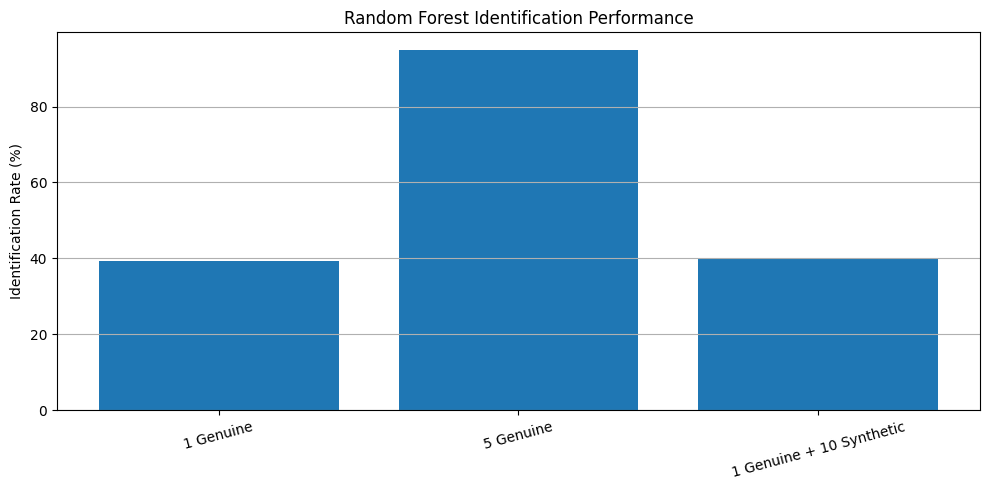

In [ ]:
# ============================================================
# IDENTIFICATION RATE
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    RF_COMPARISON["Setup"],
    RF_COMPARISON["ID Rate (%)"]
)

plt.ylabel("Identification Rate (%)")
plt.title("Random Forest Identification Performance")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

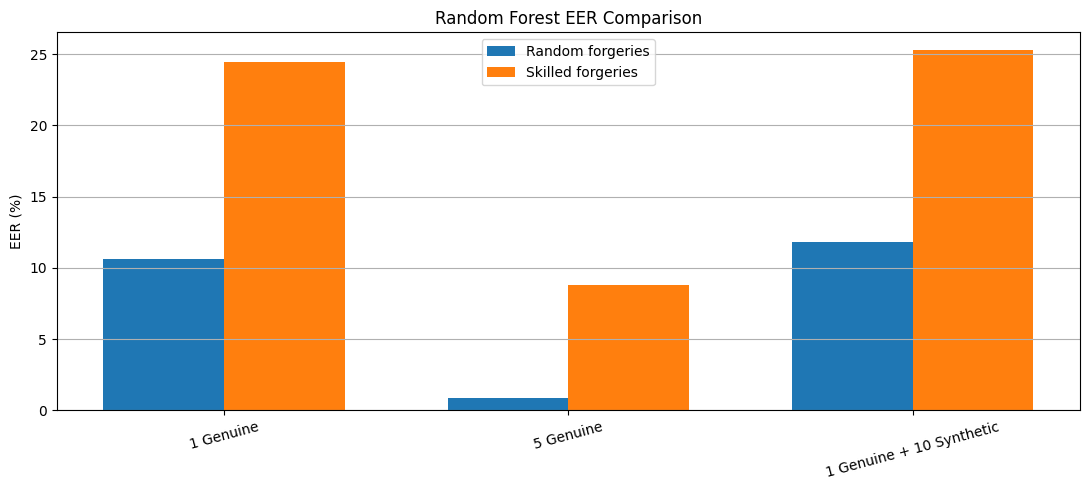

In [ ]:
# ============================================================
# EER COMPARISON
# ============================================================

positions = np.arange(
    len(RF_COMPARISON)
)

bar_width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    positions - bar_width / 2,
    RF_COMPARISON["EER Random (%)"],
    bar_width,
    label="Random forgeries"
)

plt.bar(
    positions + bar_width / 2,
    RF_COMPARISON["EER Skilled (%)"],
    bar_width,
    label="Skilled forgeries"
)

plt.xticks(
    positions,
    RF_COMPARISON["Setup"],
    rotation=15
)

plt.ylabel("EER (%)")
plt.title("Random Forest EER Comparison")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

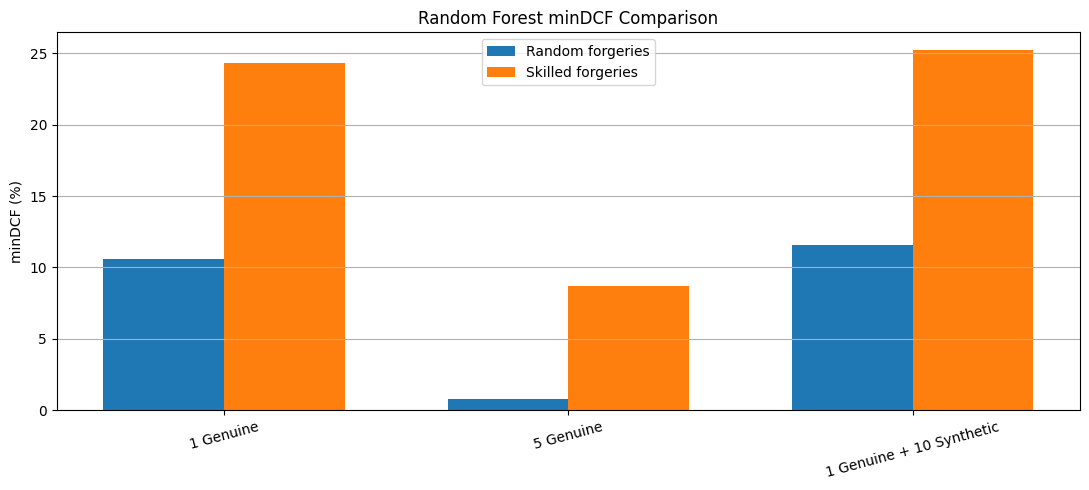

In [ ]:
# ============================================================
# minDCF COMPARISON
# ============================================================

plt.figure(figsize=(11, 5))

plt.bar(
    positions - bar_width / 2,
    RF_COMPARISON["minDCF Random (%)"],
    bar_width,
    label="Random forgeries"
)

plt.bar(
    positions + bar_width / 2,
    RF_COMPARISON["minDCF Skilled (%)"],
    bar_width,
    label="Skilled forgeries"
)

plt.xticks(
    positions,
    RF_COMPARISON["Setup"],
    rotation=15
)

plt.ylabel("minDCF (%)")
plt.title("Random Forest minDCF Comparison")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

DiagLDA :

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from scipy.fft import dct
from scipy.stats import skew, kurtosis

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# ============================================================
# PATHS
# ============================================================

DIAG_SAVE_DIR = "/content/drive/MyDrive/MCYT_DIAGLDA_EXPERIMENTS"
os.makedirs(DIAG_SAVE_DIR, exist_ok=True)

# ============================================================
# MCYT PARAMETERS
# ============================================================

USERS = get_mcyt_users(None)

TRAIN_1_GENUINE = [1]
TRAIN_5_GENUINE = [1, 2, 3, 4, 5]

TEST_GENUINE = [6, 7, 8, 9, 10]
TEST_SKILLED = list(range(0, 25))

N_SYNTHETIC = 10
RANDOM_STATE = 42

DCT_RESAMPLE_LENGTH = 160

print("Users:", len(USERS))
print("Save directory:", DIAG_SAVE_DIR)

Users: 330
Save directory: /content/drive/MyDrive/MCYT_DIAGLDA_EXPERIMENTS


In [ ]:
def sanitize_vector(vector):
    vector = np.asarray(vector, dtype=np.float64).reshape(-1)

    return np.nan_to_num(
        vector,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )


def resample_1d(vector, target_length=160):
    vector = sanitize_vector(vector)

    if len(vector) == 0:
        return np.zeros(target_length, dtype=np.float64)

    if len(vector) == 1:
        return np.full(target_length, vector[0], dtype=np.float64)

    old_axis = np.linspace(0, 1, len(vector))
    new_axis = np.linspace(0, 1, target_length)

    return np.interp(new_axis, old_axis, vector)


def safe_statistics(vector):
    """
    8 features:
    mean, std, median, IQR, min, max, skewness, kurtosis
    """
    vector = sanitize_vector(vector)

    if len(vector) == 0:
        return np.zeros(8, dtype=np.float64)

    std_value = np.std(vector, ddof=1) if len(vector) > 1 else 0.0

    skew_value = skew(
        vector,
        bias=False,
        nan_policy="omit"
    )

    kurtosis_value = kurtosis(
        vector,
        fisher=True,
        bias=False,
        nan_policy="omit"
    )

    output = np.array(
        [
            np.mean(vector),
            std_value,
            np.median(vector),
            np.percentile(vector, 75)
            - np.percentile(vector, 25),
            np.min(vector),
            np.max(vector),
            skew_value,
            kurtosis_value,
        ],
        dtype=np.float64
    )

    return np.nan_to_num(
        output,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )


def dct_features(vector, n_coefficients):
    vector = resample_1d(
        vector,
        target_length=DCT_RESAMPLE_LENGTH
    )

    coefficients = dct(
        vector,
        type=2,
        norm="ortho"
    )

    result = np.zeros(
        n_coefficients,
        dtype=np.float64
    )

    available = min(
        n_coefficients,
        len(coefficients)
    )

    result[:available] = coefficients[:available]

    return result


def extract_230_features(sequence):
    """
    sequence shape: (N, 8)

    columns:
    0 = x
    1 = y
    2 = pressure
    3 = dx
    4 = dy
    5 = dp
    6 = ddx
    7 = ddy
    """
    sequence = np.asarray(
        sequence,
        dtype=np.float64
    )

    if sequence.ndim != 2 or sequence.shape[1] < 8:
        raise ValueError(
            f"Expected shape (N, 8), got {sequence.shape}"
        )

    x = sanitize_vector(sequence[:, 0])
    y = sanitize_vector(sequence[:, 1])
    p = sanitize_vector(sequence[:, 2])

    dx = sanitize_vector(sequence[:, 3])
    dy = sanitize_vector(sequence[:, 4])
    dp = sanitize_vector(sequence[:, 5])

    ddx = sanitize_vector(sequence[:, 6])
    ddy = sanitize_vector(sequence[:, 7])

    features = []

    # ========================================================
    # PRESSURE: 32
    # ========================================================

    features.extend(safe_statistics(p))       # 8
    features.extend(safe_statistics(dp))      # 8
    features.extend(dct_features(p, 16))      # 16

    # ========================================================
    # POSITION: 113
    # ========================================================

    features.extend(safe_statistics(x))       # 8
    features.extend(safe_statistics(y))       # 8

    features.extend(dct_features(x, 48))      # 48
    features.extend(dct_features(y, 48))      # 48

    if len(x) < 2 or np.std(x) == 0 or np.std(y) == 0:
        correlation_xy = 0.0
    else:
        correlation_xy = np.corrcoef(x, y)[0, 1]

        if not np.isfinite(correlation_xy):
            correlation_xy = 0.0

    features.append(correlation_xy)           # 1

    # ========================================================
    # KINEMATICS: 84
    # ========================================================

    for channel in [dx, dy, ddx, ddy]:
        features.extend(safe_statistics(channel))  # 32

    features.extend(dct_features(dx, 24))      # 24
    features.extend(dct_features(dy, 24))      # 24

    features.extend(
        [
            np.mean(np.abs(dx)),
            np.mean(np.abs(dy)),
            np.mean(np.abs(ddx)),
            np.mean(np.abs(ddy)),
        ]
    )                                         # 4

    # ========================================================
    # OTHER: 1
    # ========================================================

    features.append(float(len(sequence)))

    features = np.asarray(
        features,
        dtype=np.float64
    )

    features = np.nan_to_num(
        features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    if len(features) != 230:
        raise RuntimeError(
            f"Expected 230 features, got {len(features)}"
        )

    return features

In [ ]:
test_sequence = load_signature_features(
    USERS[0],
    "v",
    1
)

test_vector = extract_230_features(
    test_sequence
)

print("Feature vector shape:", test_vector.shape)

Feature vector shape: (230,)


In [ ]:
def dataset_cache_path(name):
    return os.path.join(
        DIAG_SAVE_DIR,
        f"{name}.npz"
    )


def build_train_dataset(setup):
    """
    setup:
    - 1_genuine
    - 5_genuine
    - 1_genuine_10_synthetic
    """
    cache_path = dataset_cache_path(
        f"train_{setup}"
    )

    if os.path.exists(cache_path):
        data = np.load(cache_path)

        print(f"Loaded {setup} from Drive")

        return data["X"], data["y"]

    X = []
    y = []

    for user_id in tqdm(
        USERS,
        desc=f"Building {setup}"
    ):

        # ----------------------------------------------------
        # 1 genuine
        # ----------------------------------------------------
        if setup == "1_genuine":

            sequence = load_signature_features(
                user_id,
                "v",
                1
            )

            X.append(
                extract_230_features(sequence)
            )

            y.append(user_id)

        # ----------------------------------------------------
        # 5 genuine
        # ----------------------------------------------------
        elif setup == "5_genuine":

            for signature_id in TRAIN_5_GENUINE:

                sequence = load_signature_features(
                    user_id,
                    "v",
                    signature_id
                )

                X.append(
                    extract_230_features(sequence)
                )

                y.append(user_id)

        # ----------------------------------------------------
        # 1 genuine + 10 synthetic
        # ----------------------------------------------------
        elif setup == "1_genuine_10_synthetic":

            # Genuine v01
            sequence = load_signature_features(
                user_id,
                "v",
                1
            )

            X.append(
                extract_230_features(sequence)
            )

            y.append(user_id)

            # Existing synths are loaded.
            # Missing synths are generated automatically.
            synthetic_sequences = (
                get_or_generate_synthetic_sequences(
                    user_id,
                    number_synthetic=N_SYNTHETIC
                )
            )

            for synthetic_sequence in synthetic_sequences:

                X.append(
                    extract_230_features(
                        synthetic_sequence
                    )
                )

                y.append(user_id)

        else:
            raise ValueError(
                f"Unknown setup: {setup}"
            )

    X = np.asarray(
        X,
        dtype=np.float64
    )

    y = np.asarray(
        y,
        dtype=np.int32
    )

    np.savez(
        cache_path,
        X=X,
        y=y
    )

    print(f"Saved {setup} to Drive")

    return X, y


def build_genuine_test_dataset():
    cache_path = dataset_cache_path(
        "genuine_test"
    )

    if os.path.exists(cache_path):
        data = np.load(cache_path)

        print("Loaded genuine test from Drive")

        return data["X"], data["y"]

    X = []
    y = []

    for user_id in tqdm(
        USERS,
        desc="Building genuine test"
    ):

        for signature_id in TEST_GENUINE:

            sequence = load_signature_features(
                user_id,
                "v",
                signature_id
            )

            X.append(
                extract_230_features(sequence)
            )

            y.append(user_id)

    X = np.asarray(
        X,
        dtype=np.float64
    )

    y = np.asarray(
        y,
        dtype=np.int32
    )

    np.savez(
        cache_path,
        X=X,
        y=y
    )

    print("Saved genuine test to Drive")

    return X, y


def build_skilled_test_dataset():
    cache_path = dataset_cache_path(
        "skilled_test"
    )

    if os.path.exists(cache_path):
        data = np.load(cache_path)

        print("Loaded skilled test from Drive")

        return data["X"], data["y_claim"]

    X = []
    y_claim = []

    for user_id in tqdm(
        USERS,
        desc="Building skilled test"
    ):

        for signature_id in TEST_SKILLED:

            sequence = load_signature_features(
                user_id,
                "f",
                signature_id
            )

            X.append(
                extract_230_features(sequence)
            )

            y_claim.append(user_id)

    X = np.asarray(
        X,
        dtype=np.float64
    )

    y_claim = np.asarray(
        y_claim,
        dtype=np.int32
    )

    np.savez(
        cache_path,
        X=X,
        y_claim=y_claim
    )

    print("Saved skilled test to Drive")

    return X, y_claim

In [ ]:
X_TRAIN_1G, Y_TRAIN_1G = build_train_dataset(
    "1_genuine"
)

X_TRAIN_5G, Y_TRAIN_5G = build_train_dataset(
    "5_genuine"
)

X_TRAIN_1G10S, Y_TRAIN_1G10S = build_train_dataset(
    "1_genuine_10_synthetic"
)

X_GENUINE, Y_GENUINE = build_genuine_test_dataset()

X_SKILLED, Y_SKILLED_CLAIM = build_skilled_test_dataset()

print("\nShapes:")
print("1 genuine:", X_TRAIN_1G.shape)
print("5 genuine:", X_TRAIN_5G.shape)
print("1 genuine + 10 synth:", X_TRAIN_1G10S.shape)
print("Genuine test:", X_GENUINE.shape)
print("Skilled test:", X_SKILLED.shape)

Building 1_genuine:   0%|          | 0/330 [00:00<?, ?it/s]

Saved 1_genuine to Drive


Building 5_genuine:   0%|          | 0/330 [00:00<?, ?it/s]

Saved 5_genuine to Drive


Building 1_genuine_10_synthetic:   0%|          | 0/330 [00:00<?, ?it/s]

Saved 1_genuine_10_synthetic to Drive


Building genuine test:   0%|          | 0/330 [00:00<?, ?it/s]

Saved genuine test to Drive


Building skilled test:   0%|          | 0/330 [00:00<?, ?it/s]

Saved skilled test to Drive

Shapes:
1 genuine: (330, 230)
5 genuine: (1650, 230)
1 genuine + 10 synth: (3630, 230)
Genuine test: (1650, 230)
Skilled test: (8250, 230)


In [ ]:
class DiagonalLDA(BaseEstimator, ClassifierMixin):

    def __init__(
        self,
        variance_floor=1e-8
    ):
        self.variance_floor = variance_floor

    def fit(self, X, y):

        X = np.asarray(
            X,
            dtype=np.float64
        )

        y = np.asarray(y)

        self.classes_, class_indices = np.unique(
            y,
            return_inverse=True
        )

        n_classes = len(self.classes_)
        n_features = X.shape[1]

        self.class_means_ = np.zeros(
            (n_classes, n_features),
            dtype=np.float64
        )

        self.class_counts_ = np.zeros(
            n_classes,
            dtype=np.int64
        )

        for class_index in range(n_classes):

            mask = class_indices == class_index
            X_class = X[mask]

            self.class_counts_[class_index] = len(X_class)

            self.class_means_[class_index] = np.mean(
                X_class,
                axis=0
            )

        # ====================================================
        # Shared within-class diagonal variance
        # ====================================================

        residual_sum = np.zeros(
            n_features,
            dtype=np.float64
        )

        degrees_of_freedom = 0

        for class_index in range(n_classes):

            mask = class_indices == class_index
            X_class = X[mask]

            residuals = (
                X_class
                - self.class_means_[class_index]
            )

            residual_sum += np.sum(
                residuals ** 2,
                axis=0
            )

            degrees_of_freedom += max(
                len(X_class) - 1,
                0
            )

        if degrees_of_freedom > 0:

            shared_variance = (
                residual_sum
                / degrees_of_freedom
            )

        else:
            # One genuine sample per user:
            # use global variance fallback
            shared_variance = np.var(
                X,
                axis=0,
                ddof=1
            )

        shared_variance = np.nan_to_num(
            shared_variance,
            nan=1.0,
            posinf=1.0,
            neginf=1.0
        )

        self.shared_variance_ = np.maximum(
            shared_variance,
            self.variance_floor
        )

        self.class_priors_ = (
            self.class_counts_
            / np.sum(self.class_counts_)
        )

        return self

    def decision_function(self, X):

        X = np.asarray(
            X,
            dtype=np.float64
        )

        inverse_variance = (
            1.0 / self.shared_variance_
        )

        linear_term = (
            X * inverse_variance
        ) @ self.class_means_.T

        quadratic_term = 0.5 * np.sum(
            self.class_means_ ** 2
            * inverse_variance,
            axis=1
        )

        log_priors = np.log(
            np.maximum(
                self.class_priors_,
                1e-300
            )
        )

        return (
            linear_term
            - quadratic_term[None, :]
            + log_priors[None, :]
        )

    def predict_proba(self, X):

        scores = self.decision_function(X)

        scores = (
            scores
            - np.max(
                scores,
                axis=1,
                keepdims=True
            )
        )

        probabilities = np.exp(scores)

        denominator = np.sum(
            probabilities,
            axis=1,
            keepdims=True
        )

        denominator = np.maximum(
            denominator,
            1e-300
        )

        return probabilities / denominator

    def predict(self, X):

        probabilities = self.predict_proba(X)

        predicted_indices = np.argmax(
            probabilities,
            axis=1
        )

        return self.classes_[
            predicted_indices
        ]


def create_diaglda_model():

    return Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                DiagonalLDA(
                    variance_floor=1e-8
                )
            )
        ]
    )

In [ ]:
def compute_det_curve(
    genuine_scores,
    impostor_scores
):
    genuine_scores = np.asarray(
        genuine_scores,
        dtype=np.float64
    )

    impostor_scores = np.asarray(
        impostor_scores,
        dtype=np.float64
    )

    thresholds = np.unique(
        np.sort(
            np.concatenate(
                [
                    genuine_scores,
                    impostor_scores
                ]
            )
        )
    )

    thresholds = np.concatenate(
        [
            [thresholds[0] - 1e-12],
            thresholds,
            [thresholds[-1] + 1e-12]
        ]
    )

    frr = np.empty(len(thresholds))
    far = np.empty(len(thresholds))

    for index, threshold in enumerate(
        thresholds
    ):

        frr[index] = np.mean(
            genuine_scores < threshold
        )

        far[index] = np.mean(
            impostor_scores >= threshold
        )

    return frr, far, thresholds


def calculate_metrics(
    genuine_scores,
    impostor_scores
):
    frr, far, thresholds = compute_det_curve(
        genuine_scores,
        impostor_scores
    )

    eer_index = np.argmin(
        np.abs(frr - far)
    )

    eer = 0.5 * (
        frr[eer_index]
        + far[eer_index]
    )

    dcf = 0.5 * frr + 0.5 * far

    dcf_index = np.argmin(dcf)

    return {
        "EER_%": eer * 100,
        "minDCF_%": dcf[dcf_index] * 100,
        "FAR@EER_%": far[eer_index] * 100,
        "FRR@EER_%": frr[eer_index] * 100,
        "FAR@minDCF_%": far[dcf_index] * 100,
        "FRR@minDCF_%": frr[dcf_index] * 100,
        "threshold@minDCF":
            thresholds[dcf_index],
    }


def evaluate_diaglda(
    model
):
    predictions = model.predict(
        X_GENUINE
    )

    id_rate = (
        accuracy_score(
            Y_GENUINE,
            predictions
        )
        * 100
    )

    genuine_probabilities = model.predict_proba(
        X_GENUINE
    )

    skilled_probabilities = model.predict_proba(
        X_SKILLED
    )

    classes = model.named_steps[
        "classifier"
    ].classes_

    class_to_index = {
        int(label): index
        for index, label in enumerate(classes)
    }

    # ========================================================
    # Genuine scores
    # ========================================================

    genuine_scores = []

    for sample_index, true_user in enumerate(
        Y_GENUINE
    ):
        genuine_scores.append(
            genuine_probabilities[
                sample_index,
                class_to_index[int(true_user)]
            ]
        )

    genuine_scores = np.asarray(
        genuine_scores
    )

    # ========================================================
    # Random impostor scores
    # 60 wrong claims per probe
    # ========================================================

    rng = np.random.default_rng(
        RANDOM_STATE
    )

    random_scores = []

    for sample_index, true_user in enumerate(
        Y_GENUINE
    ):

        wrong_users = classes[
            classes != true_user
        ]

        selected_users = rng.choice(
            wrong_users,
            size=min(60, len(wrong_users)),
            replace=False
        )

        for claimed_user in selected_users:

            random_scores.append(
                genuine_probabilities[
                    sample_index,
                    class_to_index[int(claimed_user)]
                ]
            )

    random_scores = np.asarray(
        random_scores
    )

    # ========================================================
    # Skilled scores
    # ========================================================

    skilled_scores = []

    for sample_index, claimed_user in enumerate(
        Y_SKILLED_CLAIM
    ):

        skilled_scores.append(
            skilled_probabilities[
                sample_index,
                class_to_index[int(claimed_user)]
            ]
        )

    skilled_scores = np.asarray(
        skilled_scores
    )

    return {
        "id_rate": id_rate,
        "random_metrics": calculate_metrics(
            genuine_scores,
            random_scores
        ),
        "skilled_metrics": calculate_metrics(
            genuine_scores,
            skilled_scores
        ),
    }

In [ ]:
def run_diaglda_setup(
    setup_name,
    X_train,
    y_train
):
    model_path = os.path.join(
        DIAG_SAVE_DIR,
        f"model_{setup_name}.pkl"
    )

    results_path = os.path.join(
        DIAG_SAVE_DIR,
        f"results_{setup_name}.pkl"
    )

    if os.path.exists(model_path):

        with open(model_path, "rb") as file:
            model = pickle.load(file)

        print(f"Loaded model: {setup_name}")

    else:

        model = create_diaglda_model()

        model.fit(
            X_train,
            y_train
        )

        with open(model_path, "wb") as file:
            pickle.dump(
                model,
                file
            )

        print(f"Trained model: {setup_name}")

    results = evaluate_diaglda(model)

    with open(results_path, "wb") as file:
        pickle.dump(
            results,
            file
        )

    print("\nSetup:", setup_name)
    print(
        "ID Rate:",
        round(results["id_rate"], 4),
        "%"
    )

    print("\nRandom forgeries")
    print(results["random_metrics"])

    print("\nSkilled forgeries")
    print(results["skilled_metrics"])

    return model, results

In [ ]:
MODEL_1G, RESULTS_1G = run_diaglda_setup(
    "1_genuine",
    X_TRAIN_1G,
    Y_TRAIN_1G
)

Trained model: 1_genuine

Setup: 1_genuine
ID Rate: 77.0303 %

Random forgeries
{'EER_%': np.float64(5.163636363636363), 'minDCF_%': np.float64(5.03030303030303), 'FAR@EER_%': np.float64(5.175757575757576), 'FRR@EER_%': np.float64(5.151515151515151), 'FAR@minDCF_%': np.float64(4.6060606060606055), 'FRR@minDCF_%': np.float64(5.454545454545454), 'threshold@minDCF': np.float64(5.90366170652366e-24)}

Skilled forgeries
{'EER_%': np.float64(19.696969696969695), 'minDCF_%': np.float64(19.16969696969697), 'FAR@EER_%': np.float64(19.696969696969695), 'FRR@EER_%': np.float64(19.696969696969695), 'FAR@minDCF_%': np.float64(12.824242424242424), 'FRR@minDCF_%': np.float64(25.515151515151512), 'threshold@minDCF': np.float64(0.9950566165290479)}


In [ ]:
MODEL_5G, RESULTS_5G = run_diaglda_setup(
    "5_genuine",
    X_TRAIN_5G,
    Y_TRAIN_5G
)

Trained model: 5_genuine

Setup: 5_genuine
ID Rate: 96.9091 %

Random forgeries
{'EER_%': np.float64(0.5454545454545455), 'minDCF_%': np.float64(0.4787878787878788), 'FAR@EER_%': np.float64(0.5454545454545455), 'FRR@EER_%': np.float64(0.5454545454545455), 'FAR@minDCF_%': np.float64(0.2909090909090909), 'FRR@minDCF_%': np.float64(0.6666666666666667), 'threshold@minDCF': np.float64(7.220562825876659e-55)}

Skilled forgeries
{'EER_%': np.float64(10.193939393939393), 'minDCF_%': np.float64(10.193939393939393), 'FAR@EER_%': np.float64(15.236363636363636), 'FRR@EER_%': np.float64(5.151515151515151), 'FAR@minDCF_%': np.float64(15.236363636363636), 'FRR@minDCF_%': np.float64(5.151515151515151), 'threshold@minDCF': np.float64(1.0)}


In [ ]:
MODEL_1G10S, RESULTS_1G10S = run_diaglda_setup(
    "1_genuine_10_synthetic",
    X_TRAIN_1G10S,
    Y_TRAIN_1G10S
)

Trained model: 1_genuine_10_synthetic

Setup: 1_genuine_10_synthetic
ID Rate: 74.1212 %

Random forgeries
{'EER_%': np.float64(6.755050505050505), 'minDCF_%': np.float64(6.7035353535353535), 'FAR@EER_%': np.float64(3.631313131313131), 'FRR@EER_%': np.float64(9.878787878787879), 'FAR@minDCF_%': np.float64(3.407070707070707), 'FRR@minDCF_%': np.float64(10.0), 'threshold@minDCF': np.float64(1.0218606e-316)}

Skilled forgeries
{'EER_%': np.float64(21.07878787878788), 'minDCF_%': np.float64(20.1030303030303), 'FAR@EER_%': np.float64(21.066666666666666), 'FRR@EER_%': np.float64(21.09090909090909), 'FAR@minDCF_%': np.float64(13.296969696969697), 'FRR@minDCF_%': np.float64(26.90909090909091), 'threshold@minDCF': np.float64(1.0)}


In [ ]:
summary_rows = []

for setup_name, results in [
    ("1 Genuine", RESULTS_1G),
    ("5 Genuine", RESULTS_5G),
    (
        "1 Genuine + 10 Synthetic",
        RESULTS_1G10S
    ),
]:

    summary_rows.append(
        {
            "Setup": setup_name,
            "ID Rate (%)":
                results["id_rate"],
            "EER Random (%)":
                results["random_metrics"][
                    "EER_%"
                ],
            "EER Skilled (%)":
                results["skilled_metrics"][
                    "EER_%"
                ],
            "minDCF Random (%)":
                results["random_metrics"][
                    "minDCF_%"
                ],
            "minDCF Skilled (%)":
                results["skilled_metrics"][
                    "minDCF_%"
                ],
        }
    )

DIAGLDA_RESULTS = pd.DataFrame(
    summary_rows
)

display(DIAGLDA_RESULTS)

DIAGLDA_RESULTS.to_csv(
    os.path.join(
        DIAG_SAVE_DIR,
        "diaglda_final_results.csv"
    ),
    index=False
)

,Setup,ID Rate (%),EER Random (%),EER Skilled (%),minDCF Random (%),minDCF Skilled (%)
0,1 Genuine,77.030303,5.163636,19.696970,5.030303,19.169697
1,5 Genuine,96.909091,0.545455,10.193939,0.478788,10.193939
2,1 Genuine + 10 Synthetic,74.121212,6.755051,21.078788,6.703535,20.103030
